# Support Vector Machines : Python Programming and Investigation Problems Industry Applications

All twelve problems and the integrated project, in one reproducible notebook. Random seeds are fixed (42). Preprocessing is always fitted on training data only; model selection uses validation data or cross-validation; the final test set is used only after the complete procedure has been chosen. Each problem ends with a written interpretation.


In [1]:
import time, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_classification, make_moons, make_circles
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, GroupKFold,
                                     cross_val_predict, cross_val_score)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, SVR, OneClassSVM, LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.kernel_approximation import RBFSampler, Nystroem
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             average_precision_score, roc_auc_score, precision_recall_curve,
                             brier_score_loss, log_loss, mean_absolute_error, mean_squared_error)

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42
BLUE, RED = "#2E5B8A", "#C0392B"

def plot_decision(ax, score_fn, X, y, title, levels=True, pad=0.6, n=250, xlim=None, ylim=None):
    # shaded predicted regions + boundary (solid) + margin lines at -1/+1 (dashed)
    lo = X.min(0) - pad; hi = X.max(0) + pad
    if xlim: lo[0], hi[0] = xlim
    if ylim: lo[1], hi[1] = ylim
    xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], n), np.linspace(lo[1], hi[1], n))
    Z = score_fn(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, alpha=0.12, colors=[RED, BLUE], levels=[-0.5, 0.5, 1.5])
    ax.contour(xx, yy, Z, levels=[0], colors="k", linewidths=1.5)
    if levels:
        ax.contour(xx, yy, Z, levels=[-1, 1], colors="k", linestyles="--", linewidths=0.8)
    ax.scatter(X[:, 0], X[:, 1], c=np.where(np.asarray(y) > 0, BLUE, RED), s=14, edgecolor="k", linewidth=0.3)
    ax.set_title(title, fontsize=10)

def metrics_row(y_true, y_pred, score=None):
    d = dict(acc=accuracy_score(y_true, y_pred), prec=precision_score(y_true, y_pred, zero_division=0),
             rec=recall_score(y_true, y_pred), f1=f1_score(y_true, y_pred))
    if score is not None: d["ap"] = average_precision_score(y_true, score)
    return d


C:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\_param_validation.py:11: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.4.6)
  from scipy.sparse import csr_matrix, issparse


---
## Problem 1: Implement a linear SVM from scratch

**Data:** `make_blobs` (300 points, 2 classes, std 1.5, seed 42), labels in {-1, +1}, stratified 70:30 split, inputs standardized with training statistics.  
**Objective:** J(w, b) = (lambda/2)||w||^2 + (1/n) sum max{0, 1 - y_i (w'x_i + b)}, with b not regularized and a zero hinge subgradient at margin exactly 1.


In [2]:
X, y01 = make_blobs(n_samples=300, centers=2, cluster_std=1.5, random_state=SEED)
y = np.where(y01 == 1, 1, -1)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
scaler1 = StandardScaler().fit(X_tr)
Z_tr, Z_te = scaler1.transform(X_tr), scaler1.transform(X_te)
n = len(y_tr); lam = 0.01
print("train n =", n, "| test n =", len(y_te), "| class counts (train):", {int(k): int((y_tr == k).sum()) for k in (-1, 1)})

# (a) building blocks
def decision_scores(w, b, X): return X @ w + b
def predict(w, b, X): return np.where(decision_scores(w, b, X) >= 0, 1, -1)
def hinge_loss(w, b, X, y): return np.maximum(0.0, 1.0 - y * decision_scores(w, b, X))
def objective(w, b, X, y, lam): return 0.5 * lam * (w @ w) + hinge_loss(w, b, X, y).mean()

# (b) batch subgradient descent (no scikit-learn SVM code)
def train_svm(X, y, lam, lr, iters=3000, decay=False):
    n, d = X.shape; w = np.zeros(d); b = 0.0; hist = []
    for t in range(iters):
        margin = y * decision_scores(w, b, X)
        active = margin < 1                     # margin exactly 1 -> subgradient 0
        grad_w = lam * w - (y[active, None] * X[active]).sum(0) / n
        grad_b = -y[active].sum() / n           # b is not regularized
        step = lr / np.sqrt(t + 1) if decay else lr
        w = w - step * grad_w; b = b - step * grad_b
        hist.append(objective(w, b, X, y, lam))
    return w, b, np.array(hist)

# (c) at least three learning rates (+ one decaying schedule)
runs = {}
for lr in [0.01, 0.1, 0.5, 2.0]:
    runs[f"constant lr={lr}"] = train_svm(Z_tr, y_tr, lam, lr)
runs["decaying lr0=2.0/sqrt(t)"] = train_svm(Z_tr, y_tr, lam, 2.0, decay=True)

# (g) reference solver: C = 1 / (n * lambda)
C_ref = 1.0 / (n * lam)
svc = SVC(kernel="linear", C=C_ref, tol=1e-6).fit(Z_tr, y_tr)
w_ref, b_ref = svc.coef_[0], svc.intercept_[0]
J_ref = objective(w_ref, b_ref, Z_tr, y_tr, lam)

rows = []
for name, (w, b, h) in runs.items():
    rows.append(dict(run=name, final_J=h[-1], best_J=h.min(), w1=w[0], w2=w[1], b=b,
                     train_acc=accuracy_score(y_tr, predict(w, b, Z_tr)), test_acc=accuracy_score(y_te, predict(w, b, Z_te))))
rows.append(dict(run=f"SVC linear (C={C_ref:.3f})", final_J=J_ref, best_J=J_ref, w1=w_ref[0], w2=w_ref[1], b=b_ref,
                 train_acc=accuracy_score(y_tr, svc.predict(Z_tr)), test_acc=accuracy_score(y_te, svc.predict(Z_te))))
t1 = pd.DataFrame(rows).round(4); print(t1.to_string(index=False))


train n = 210 | test n = 90 | class counts (train): {-1: 105, 1: 105}
                     run  final_J  best_J     w1      w2       b  train_acc  test_acc
        constant lr=0.01   0.0230  0.0230 1.0751 -1.0649 -0.0082        1.0       1.0
         constant lr=0.1   0.0227  0.0227 1.2424 -1.2136 -0.0081        1.0       1.0
         constant lr=0.5   0.0227  0.0227 1.2544 -1.2243 -0.0071        1.0       1.0
         constant lr=2.0   0.0227  0.0227 1.2544 -1.2243  0.0095        1.0       1.0
decaying lr0=2.0/sqrt(t)   0.0227  0.0227 1.2743 -1.2466  0.0155        1.0       1.0
    SVC linear (C=0.476)   0.0227  0.0227 1.2544 -1.2243  0.0142        1.0       1.0


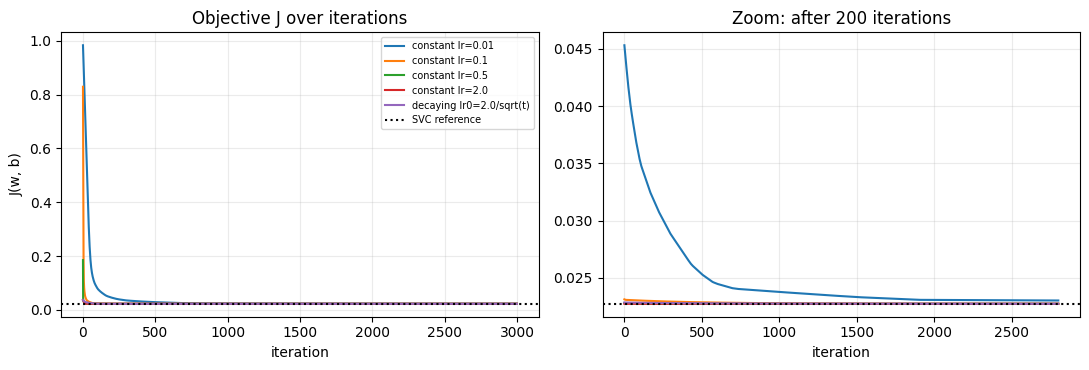

In [3]:
# (d) objective across iterations
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, (w, b, h) in runs.items():
    ax[0].plot(h, label=name); ax[1].plot(h[200:], label=name)
ax[0].axhline(J_ref, color="k", ls=":", label="SVC reference")
ax[1].axhline(J_ref, color="k", ls=":")
ax[0].set_title("Objective J over iterations"); ax[1].set_title("Zoom: after 200 iterations")
ax[0].set_xlabel("iteration"); ax[1].set_xlabel("iteration"); ax[0].set_ylabel("J(w, b)"); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()


run used for the plots: constant lr=2.0 | w = [ 1.254 -1.224] b = 0.01


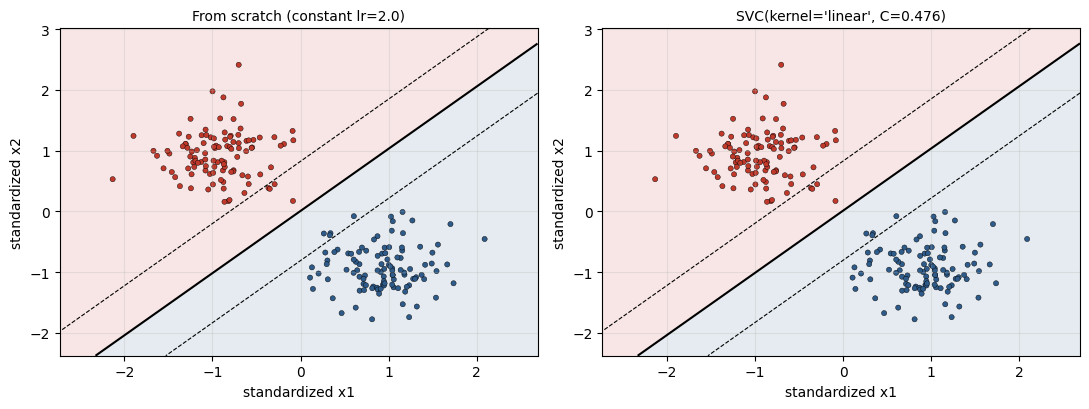

margin <= 1 : 8 of 210 training points
  strictly inside the margin (m < 1-0.02): 8  (of which misclassified, m < 0: 0)
  on the margin (|m-1| <= 0.02)            : 0
SVC for comparison: support vectors = 8 | inside (m<1-1e-3): 8 | on margin (free SVs): 0


In [4]:
# (e) boundary and canonical margin lines in standardized coordinates (best-converged run)
best_name = min(runs, key=lambda k: runs[k][2][-1]); w_b, b_b, _ = runs[best_name]
print("run used for the plots:", best_name, "| w =", w_b.round(3), "b =", round(b_b, 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
plot_decision(ax[0], lambda P: decision_scores(w_b, b_b, P), Z_tr, y_tr, f"From scratch ({best_name})")
plot_decision(ax[1], lambda P: svc.decision_function(P), Z_tr, y_tr, f"SVC(kernel='linear', C={C_ref:.3f})")
for a in ax: a.set_xlabel("standardized x1"); a.set_ylabel("standardized x2")
plt.tight_layout(); plt.show()

# (f) points whose signed functional margin is at most 1
m = y_tr * decision_scores(w_b, b_b, Z_tr); tol = 0.02
inside, on = m < 1 - tol, np.abs(m - 1) <= tol
print(f"margin <= 1 : {int((m <= 1 + tol).sum())} of {n} training points")
print(f"  strictly inside the margin (m < 1-{tol}): {int(inside.sum())}  (of which misclassified, m < 0: {int((m < 0).sum())})")
print(f"  on the margin (|m-1| <= {tol})            : {int(on.sum())}")
m_ref = y_tr * svc.decision_function(Z_tr)
print("SVC for comparison: support vectors =", int(svc.n_support_.sum()), "| inside (m<1-1e-3):", int((m_ref < 1 - 1e-3).sum()),
      "| on margin (free SVs):", int((np.abs(m_ref - 1) <= 1e-3).sum()))


**(h) Why the two solutions can differ slightly.** The code below measures how close each run is to the SVC optimum.

In [5]:
w_dir = lambda w: w / np.linalg.norm(w)
for name, (w, b, h) in runs.items():
    cos = float(w_dir(w) @ w_dir(w_ref))
    print(f"{name:28s} J gap to SVC = {h[-1] - J_ref:+.5f} | cosine(w, w_svc) = {cos:.4f} | |w| = {np.linalg.norm(w):.3f} vs {np.linalg.norm(w_ref):.3f}")
print("SVC |w| =", round(np.linalg.norm(w_ref), 3), "| tolerance used for SVC: 1e-6")


constant lr=0.01             J gap to SVC = +0.00029 | cosine(w, w_svc) = 1.0000 | |w| = 1.513 vs 1.753
constant lr=0.1              J gap to SVC = +0.00000 | cosine(w, w_svc) = 1.0000 | |w| = 1.737 vs 1.753
constant lr=0.5              J gap to SVC = +0.00000 | cosine(w, w_svc) = 1.0000 | |w| = 1.753 vs 1.753
constant lr=2.0              J gap to SVC = +0.00000 | cosine(w, w_svc) = 1.0000 | |w| = 1.753 vs 1.753
decaying lr0=2.0/sqrt(t)     J gap to SVC = +0.00000 | cosine(w, w_svc) = 1.0000 | |w| = 1.783 vs 1.753
SVC |w| = 1.753 | tolerance used for SVC: 1e-6


**Interpretation.**

*Convergence.* The three larger constant learning rates (0.1, 0.5, 2.0) and the decaying schedule all end at an objective of about 0.0227, the same value that `SVC(kernel="linear", C=1/(n*lambda))` reaches, and their weight vectors point in the same direction as the SVC solution (cosine 1.0000). The smallest rate (0.01) is simply too slow: after 3,000 iterations its objective is still 0.0230 and its weight vector is shorter (|w| = 1.51 against 1.75), so it has not converged. A larger step size reaches the optimum value quickly, but with a constant step the subgradient never shrinks to zero, so the intercept keeps jittering (b = 0.0095 for lr = 2.0 against 0.0142 for SVC). The decaying step (2.0/sqrt(t)) smooths this out but is slightly off in the other direction (|w| = 1.78).

*Margins.* The classes are separable and the test accuracy is 1.0 for every run, but with lambda = 0.01 (C = 0.476) the margin is soft: 8 of the 210 training points have a signed margin below 1, all of them correctly classified and **inside** the margin, and none lies exactly on it. The reference SVC agrees: 8 support vectors, all bounded (alpha = C, inside the margin), none free.

*(h) Why differences can remain.* The from-scratch method is first-order and stops after a fixed number of iterations, so it can stop short (lr = 0.01) or keep oscillating (constant step). The SVC solver works on the dual and stops when the optimality conditions are met to a tolerance (here 1e-6), and it gets b from the KKT conditions, which gives a cleaner intercept. Both solve the same convex problem, so the objective values agree to four decimals while individual coefficients can differ in the third or fourth digit.

---
## Problem 2: The effect of the penalty parameter C

500 observations from `make_classification` (2 informative features, no redundant, one cluster per class, `class_sep=0.8`, `flip_y=0.08`, seed 42); stratified train / validation / test (60 / 20 / 20).


In [6]:
X, y = make_classification(n_samples=500, n_features=2, n_informative=2, n_redundant=0, n_clusters_per_class=1,
                           class_sep=0.8, flip_y=0.08, random_state=SEED)
y2 = np.where(y == 1, 1, -1)
X_rest, X_te2, y_rest, y_te2 = train_test_split(X, y2, test_size=0.2, stratify=y2, random_state=SEED)
X_tr2, X_va2, y_tr2, y_va2 = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("sizes train/val/test:", len(y_tr2), len(y_va2), len(y_te2))

Cs = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
models2, rows = {}, []
for C in Cs:
    mdl = SVC(kernel="linear", C=C, max_iter=-1).fit(X_tr2, y_tr2); models2[C] = mdl
    assert mdl.fit_status_ == 0, f"solver did not converge for C={C}"
    f_tr = mdl.decision_function(X_tr2); wn = np.linalg.norm(mdl.coef_[0])
    rows.append(dict(C=C, train_acc=accuracy_score(y_tr2, mdl.predict(X_tr2)), val_acc=accuracy_score(y_va2, mdl.predict(X_va2)),
                     w_norm=wn, margin_width=2 / wn, n_SV=int(mdl.n_support_.sum()),
                     n_margin_violations=int((y_tr2 * f_tr < 1 - 1e-3).sum()), total_hinge=float(np.maximum(0, 1 - y_tr2 * f_tr).sum())))
t2 = pd.DataFrame(rows); print(t2.round(4).to_string(index=False))


sizes train/val/test: 300 100 100
       C  train_acc  val_acc  w_norm  margin_width  n_SV  n_margin_violations  total_hinge
   0.001     0.5567     0.56  0.2240        8.9300   296                  296     245.8398
   0.010     0.8033     0.72  0.7591        2.6346   220                  218     160.5092
   0.100     0.8333     0.73  1.3339        1.4993   160                  155     140.2896
   1.000     0.8433     0.74  1.5358        1.3023   142                  139     138.8223
  10.000     0.8400     0.74  1.5455        1.2941   141                  137     138.8143
 100.000     0.8400     0.74  1.5455        1.2941   141                  137     138.8141
1000.000     0.8400     0.74  1.5458        1.2939   141                  137     138.8143


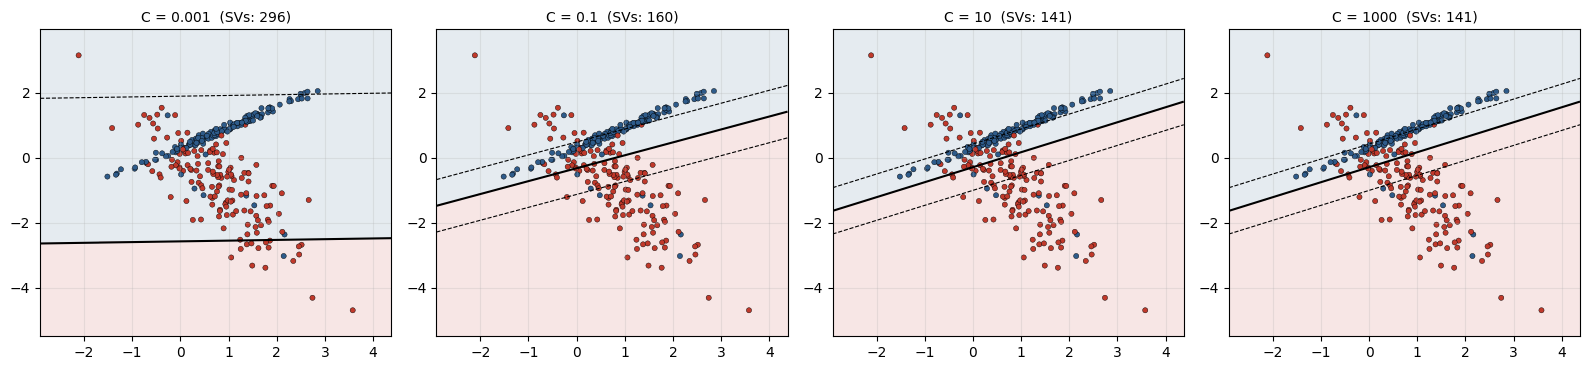

selected C = 1.0 | validation acc = 0.74
test accuracy of the selected model: 0.79
test metrics: {'acc': 0.79, 'prec': np.float64(0.714), 'rec': np.float64(0.98), 'f1': np.float64(0.826)}
n_SV non-increasing in C?    True | n_SV: [296, 220, 160, 142, 141, 141, 141]
val acc non-decreasing in C? True | val acc: [0.56, 0.72, 0.73, 0.74, 0.74, 0.74, 0.74]
training violations non-increasing? True
total hinge non-increasing? True
over 30 repeated experiments: support-vector count increased somewhere along the C path in 0 runs; validation accuracy dropped somewhere along the C path in 13 runs


In [7]:
# (d) representative boundaries
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, C in zip(ax, [0.001, 0.1, 10, 1000]):
    plot_decision(a, models2[C].decision_function, X_tr2, y_tr2, f"C = {C}  (SVs: {int(models2[C].n_support_.sum())})", pad=0.8)
plt.tight_layout(); plt.show()

# (e) select C on validation accuracy (ties -> the smaller C, the simpler model)
best_val = t2.val_acc.max(); C_sel = float(t2[t2.val_acc == best_val].C.min())
sel = models2[C_sel]
print("selected C =", C_sel, "| validation acc =", round(best_val, 4))
print("test accuracy of the selected model:", round(accuracy_score(y_te2, sel.predict(X_te2)), 4))
print("test metrics:", {k: round(v, 3) for k, v in metrics_row(y_te2, sel.predict(X_te2)).items()})

# (f) does a larger C ALWAYS give fewer support vectors / better validation accuracy?
nsv = t2.n_SV.values; va = t2.val_acc.values
print("n_SV non-increasing in C?   ", bool(np.all(np.diff(nsv) <= 0)), "| n_SV:", nsv.tolist())
print("val acc non-decreasing in C?", bool(np.all(np.diff(va) >= -1e-12)), "| val acc:", np.round(va, 3).tolist())
print("training violations non-increasing?", bool(np.all(np.diff(t2.n_margin_violations.values) <= 0)))
print("total hinge non-increasing?", bool(np.all(np.diff(t2.total_hinge.values) <= 1e-2)))

# is the monotone behaviour GENERAL?  repeat the experiment on 30 different random datasets / splits
viol_sv = viol_acc = 0
for s_ in range(30):
    Xs, ys = make_classification(n_samples=500, n_features=2, n_informative=2, n_redundant=0, n_clusters_per_class=1,
                                 class_sep=0.8, flip_y=0.08, random_state=100 + s_)
    ys = np.where(ys == 1, 1, -1)
    Xa, Xb_, ya, yb_ = train_test_split(Xs, ys, test_size=0.2, stratify=ys, random_state=s_)
    Xa, Xv, ya, yv = train_test_split(Xa, ya, test_size=0.25, stratify=ya, random_state=s_)
    nsv_s, va_s = [], []
    for C in Cs:
        m_ = SVC(kernel="linear", C=C, max_iter=-1).fit(Xa, ya); nsv_s.append(int(m_.n_support_.sum())); va_s.append(m_.score(Xv, yv))
    viol_sv += int(np.any(np.diff(nsv_s) > 0)); viol_acc += int(np.any(np.diff(va_s) < -1e-12))
print(f"over 30 repeated experiments: support-vector count increased somewhere along the C path in {viol_sv} runs; "
      f"validation accuracy dropped somewhere along the C path in {viol_acc} runs")


**Interpretation.**

The comparison table shows the usual pattern. With C = 0.001 the model is almost all slack: the weight norm is tiny (0.22), the margin is very wide (8.9), nearly every training point (296 of 300) is a support vector and the validation accuracy is only 0.56. As C grows the weight norm increases (the margin narrows) and the accuracy rises to 0.73 to 0.74 by C = 0.1 to 1. From C = 10 to 1000 the solution is essentially identical (weight norm 1.5455, 141 support vectors, validation accuracy 0.74): the data are noisy (8% of labels were flipped), so even a huge C cannot remove all violations and the optimum stops changing. The best possible training accuracy is limited to roughly 0.84.

*(e) Selection.* The best validation accuracy (0.74) is reached from C = 1 upward; I take the smallest such C, 1.0. Its test accuracy is 0.79 (precision 0.714, recall 0.98, F1 0.826). With only 100 validation and 100 test points, differences of one or two points are within noise.

*(f) Does a larger C always give fewer support vectors or better validation accuracy?* In this single run the support-vector count never increased (296, 220, 160, 142, 141, 141, 141) and the validation accuracy never decreased, but both flattened out, so "always better" is not supported: past C = 1 nothing improved. The repeated experiment over 30 random datasets and splits makes the point clearly: the support-vector count never increased along the C path in any of the 30 runs, but the validation accuracy dropped somewhere along the path in 13 of the 30. So fewer support vectors with larger C held here, while better validation accuracy with larger C is not guaranteed, because a large C fits the noise.

*(g) Margin versus misclassification.* The geometric margin 2/||w|| measures how much empty space the boundary leaves in the feature space. The misclassification count only counts points on the wrong side. They measure different things and can move in opposite directions: a wide margin (small C) can still misclassify many points if the boundary is poorly placed, and a narrow margin can have fewer errors. In the table, at C = 1 there are about 139 training points with y f < 1 (inside or beyond the margin) but only about 16% of the training points are misclassified: being inside the margin is a much weaker condition than being misclassified. What the margin buys is stability to small movements of the data, which matters for generalization.

---
## Problem 3: The interaction between C and gamma

600 `make_moons` observations (noise 0.25, seed 42); stratified 25% test set; pipeline = StandardScaler + RBF SVM; 5-fold stratified cross-validation on the rest over a 5 x 5 grid of C and gamma.


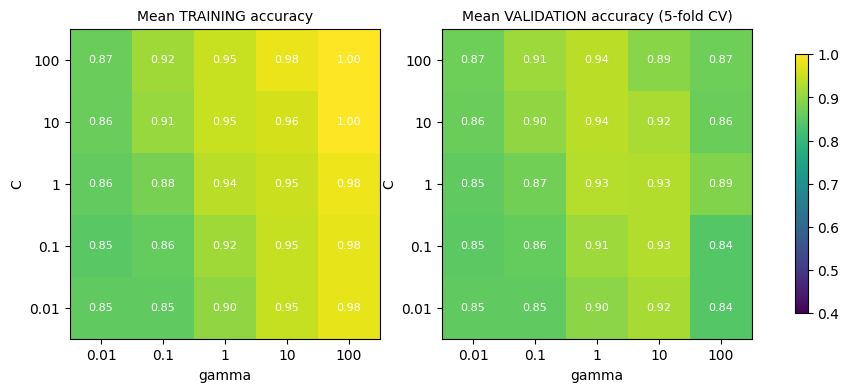

best CV configuration: {'svc__C': 10, 'svc__gamma': 1} | CV accuracy: 0.9378


In [8]:
X3, y3 = make_moons(n_samples=600, noise=0.25, random_state=SEED)
X3_tr, X3_te, y3_tr, y3_te = train_test_split(X3, y3, test_size=0.25, stratify=y3, random_state=SEED)
Cg = [0.01, 0.1, 1, 10, 100]; Gg = [0.01, 0.1, 1, 10, 100]
pipe3 = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
gs3 = GridSearchCV(pipe3, {"svc__C": Cg, "svc__gamma": Gg}, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                   return_train_score=True, n_jobs=1).fit(X3_tr, y3_tr)
tr = gs3.cv_results_["mean_train_score"].reshape(5, 5)   # rows = C, columns = gamma (param order is alphabetical: C then gamma)
va = gs3.cv_results_["mean_test_score"].reshape(5, 5)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, M, t in zip(ax, [tr, va], ["Mean TRAINING accuracy", "Mean VALIDATION accuracy (5-fold CV)"]):
    im = a.imshow(M, cmap="viridis", vmin=0.4, vmax=1.0, origin="lower")
    a.set_xticks(range(5)); a.set_xticklabels(Gg); a.set_yticks(range(5)); a.set_yticklabels(Cg)
    a.set_xlabel("gamma"); a.set_ylabel("C"); a.set_title(t, fontsize=10); a.grid(False)
    for i in range(5):
        for j in range(5): a.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
plt.colorbar(im, ax=ax, shrink=0.8); plt.show()
print("best CV configuration:", gs3.best_params_, "| CV accuracy:", round(gs3.best_score_, 4))


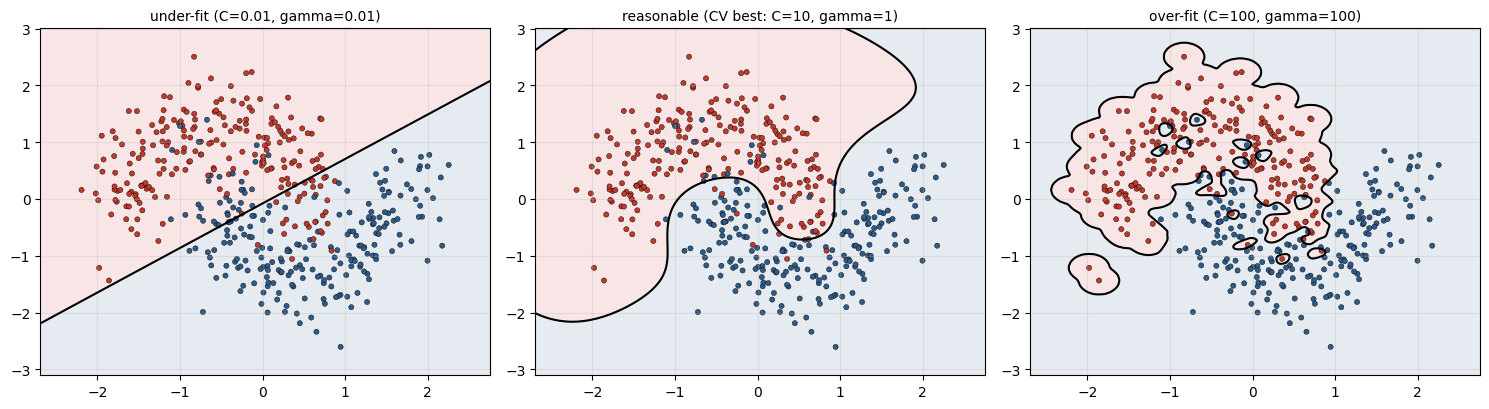

                             config  train_acc  n_SV  SV_share
     under-fit (C=0.01, gamma=0.01)      0.853   450     1.000
reasonable (CV best: C=10, gamma=1)      0.949    82     0.182
        over-fit (C=100, gamma=100)      1.000   386     0.858
TEST: {'acc': 0.947, 'prec': np.float64(0.947), 'rec': np.float64(0.947), 'f1': np.float64(0.947), 'ap': np.float64(0.975)}
confusion matrix [[TN, FP], [FN, TP]]: [[71, 4], [4, 71]]
best validation accuracy per gamma (over all C): {0.01: np.float64(0.867), 0.1: np.float64(0.911), 1: np.float64(0.938), 10: np.float64(0.931), 100: np.float64(0.887)}
best validation accuracy per C     (over all gamma): {0.01: np.float64(0.922), 0.1: np.float64(0.931), 1: np.float64(0.933), 10: np.float64(0.938), 100: np.float64(0.938)}


In [9]:
# (d)+(e) boundaries for under-fitting, reasonable and over-fitting configurations, plus support-vector counts
configs = {"under-fit (C=0.01, gamma=0.01)": (0.01, 0.01),
           f"reasonable (CV best: C={gs3.best_params_['svc__C']}, gamma={gs3.best_params_['svc__gamma']})": (gs3.best_params_["svc__C"], gs3.best_params_["svc__gamma"]),
           "over-fit (C=100, gamma=100)": (100, 100)}
sc3 = StandardScaler().fit(X3_tr); Z3_tr = sc3.transform(X3_tr)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2)); rows = []
for a, (name, (C, g)) in zip(ax, configs.items()):
    m = SVC(kernel="rbf", C=C, gamma=g).fit(Z3_tr, y3_tr)
    plot_decision(a, m.decision_function, Z3_tr, np.where(y3_tr == 1, 1, -1), name, levels=False, pad=0.5)
    rows.append(dict(config=name, train_acc=m.score(Z3_tr, y3_tr), n_SV=int(m.n_support_.sum()), SV_share=m.n_support_.sum() / len(y3_tr)))
plt.tight_layout(); plt.show(); print(pd.DataFrame(rows).round(3).to_string(index=False))
# (f) final evaluation on the untouched test set
best3 = gs3.best_estimator_
p3 = best3.predict(X3_te)
print("TEST:", {k: round(v, 3) for k, v in metrics_row(y3_te, p3, best3.decision_function(X3_te)).items()})
print("confusion matrix [[TN, FP], [FN, TP]]:", confusion_matrix(y3_te, p3).tolist())
# (g) can a larger C rescue a bad gamma?  best CV accuracy reachable for each gamma
print("best validation accuracy per gamma (over all C):", dict(zip(Gg, np.round(va.max(0), 3))))
print("best validation accuracy per C     (over all gamma):", dict(zip(Cg, np.round(va.max(1), 3))))


**Interpretation.**

The heatmaps show the classic picture. Training accuracy (left) keeps rising towards 1.0 as C and gamma grow, while validation accuracy (right) rises and then falls. The best cross-validated configuration is C = 10, gamma = 1 (CV accuracy 0.938), which gives a **test accuracy of 0.947** (precision, recall and F1 all 0.947; confusion matrix [[71, 4], [4, 71]]; average precision 0.975).

The three boundary plots illustrate the regimes:

* **Under-fit (C = 0.01, gamma = 0.01):** a nearly straight boundary, training accuracy 0.853, and every one of the 450 training points is a support vector (share 1.00), because almost every point violates the margin.
* **Reasonable (C = 10, gamma = 1):** a smooth curve that follows the two moons, training accuracy 0.949 and only 82 support vectors (18%).
* **Over-fit (C = 100, gamma = 100):** islands around individual points, training accuracy 1.00 and 386 support vectors (86%): the model has memorized the training set.

*(g) Why C cannot always compensate for a bad gamma.* Gamma decides the shape of the functions the model can build; C decides how hard it tries to fit with them. With gamma = 0.01 the kernel is almost linear, so the boundary cannot bend around the moons however large C is: the best validation accuracy at that gamma, over all C, is only 0.867. With gamma = 100 the similarity is so local that the model can only draw small bumps; raising or lowering C changes how many points it tries to fit, but the shape stays too wiggly, and the best accuracy there is 0.887. At gamma = 1 the best accuracy is 0.938. In contrast, the best accuracy reachable over all gammas changes only from 0.922 to 0.938 as C goes from 0.01 to 100. So gamma sets the ceiling and C moves you around beneath it; the two must be tuned together.

---
## Problem 4: Matching kernels to data geometry

Three datasets of 500 points each: near-linearly separable blobs, a noisy XOR (coordinates uniform on [-1, 1]^2, class 1 when x1*x2 > 0, 5% of labels flipped), and concentric circles. Stratified 70/30 split per dataset; parameters tuned by cross-validation inside the training data only.


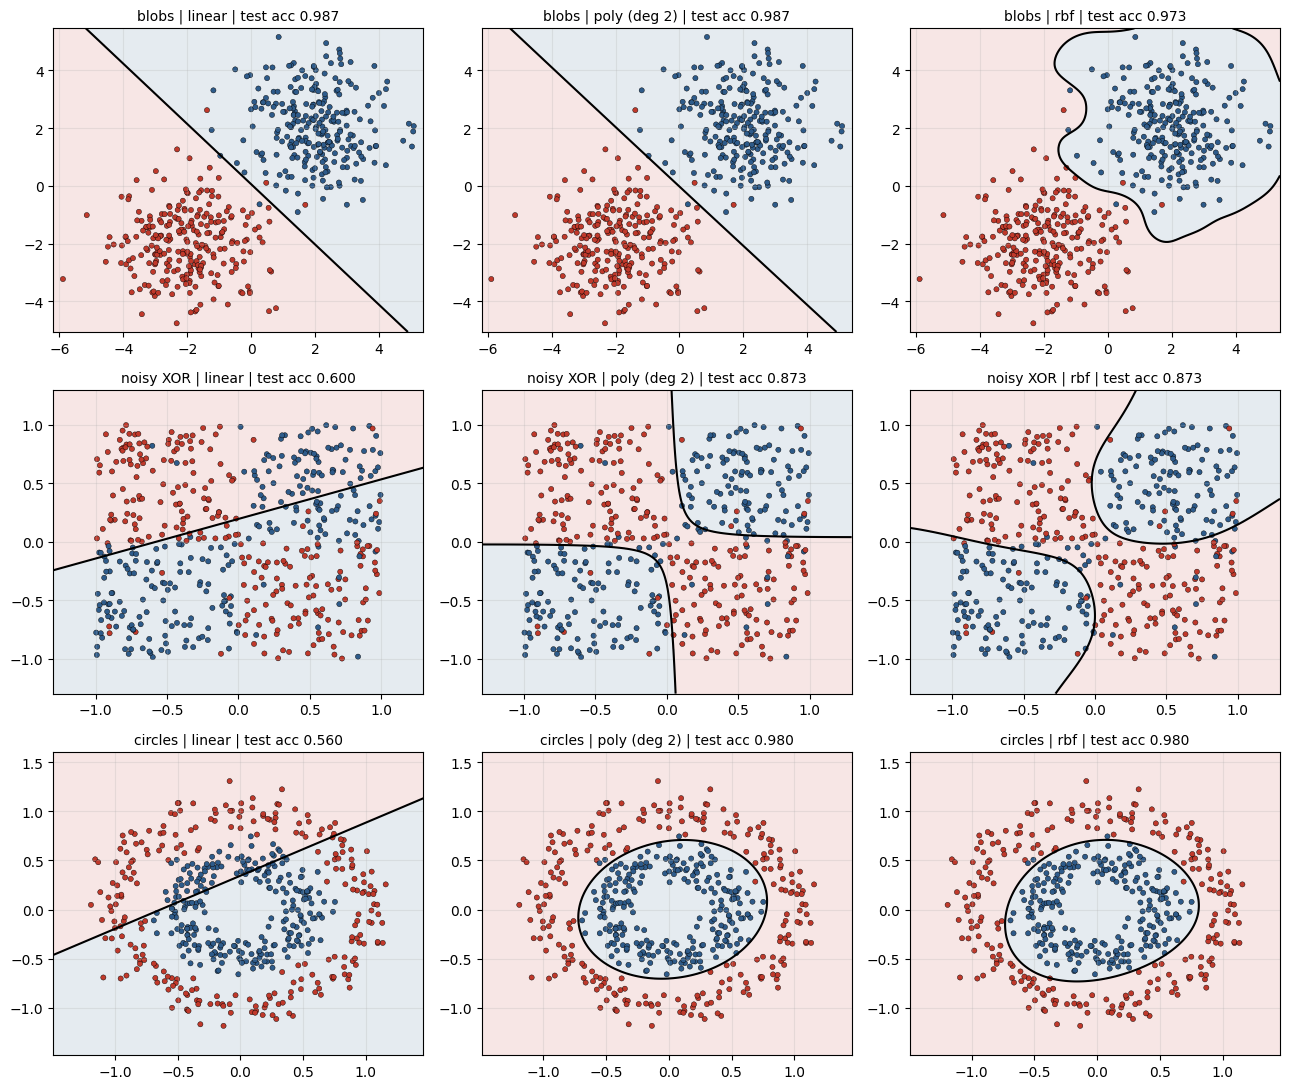

  dataset       kernel  cv_acc  test_acc                      best
    blobs       linear   0.991     0.987               {'C': 0.01}
    blobs poly (deg 2)   0.991     0.987 {'C': 0.01, 'gamma': 0.1}
    blobs          rbf   0.994     0.973     {'C': 1, 'gamma': 10}
noisy XOR       linear   0.557     0.600                 {'C': 10}
noisy XOR poly (deg 2)   0.911     0.873    {'C': 10, 'gamma': 10}
noisy XOR          rbf   0.926     0.873      {'C': 1, 'gamma': 1}
  circles       linear   0.529     0.560                  {'C': 1}
  circles poly (deg 2)   0.994     0.980     {'C': 1, 'gamma': 10}
  circles          rbf   0.991     0.980  {'C': 100, 'gamma': 0.1}

test accuracy table:
kernel     linear  poly (deg 2)    rbf
dataset                               
blobs       0.987         0.987  0.973
circles     0.560         0.980  0.980
noisy XOR   0.600         0.873  0.873


In [10]:
rng = np.random.default_rng(SEED)
Xb, yb = make_blobs(n_samples=500, centers=[(-2, -2), (2, 2)], cluster_std=1.2, random_state=SEED)
Xx = rng.uniform(-1, 1, size=(500, 2)); yx = (Xx[:, 0] * Xx[:, 1] > 0).astype(int)
flip = rng.choice(500, size=25, replace=False); yx[flip] = 1 - yx[flip]
Xc, yc = make_circles(n_samples=500, noise=0.1, factor=0.5, random_state=SEED)
datasets4 = {"blobs": (Xb, yb), "noisy XOR": (Xx, yx), "circles": (Xc, yc)}
grids4 = {"linear": ({"svc__C": [0.01, 0.1, 1, 10, 100]}, dict(kernel="linear")),
          "poly (deg 2)": ({"svc__C": [0.01, 0.1, 1, 10, 100], "svc__gamma": [0.1, 1, 10]}, dict(kernel="poly", degree=2, coef0=1)),
          "rbf": ({"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.1, 1, 10]}, dict(kernel="rbf"))}
cv4 = StratifiedKFold(5, shuffle=True, random_state=SEED)
fig, axes = plt.subplots(3, 3, figsize=(13, 11)); results4 = []; fitted4 = {}
for i, (dname, (X, y)) in enumerate(datasets4.items()):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
    for j, (kname, (grid, kw)) in enumerate(grids4.items()):
        gs = GridSearchCV(make_pipeline(StandardScaler(), SVC(**kw)), grid, cv=cv4).fit(Xtr, ytr)
        fitted4[(dname, kname)] = gs.best_estimator_
        acc = gs.score(Xte, yte)
        results4.append(dict(dataset=dname, kernel=kname, cv_acc=gs.best_score_, test_acc=acc, best=str({k.split('__')[1]: v for k, v in gs.best_params_.items()})))
        plot_decision(axes[i, j], gs.best_estimator_.decision_function, X, np.where(y == 1, 1, -1), f"{dname} | {kname} | test acc {acc:.3f}", levels=False, pad=0.3)
plt.tight_layout(); plt.show()
t4 = pd.DataFrame(results4); print(t4.round(3).to_string(index=False))
print(); print("test accuracy table:"); print(t4.pivot(index="dataset", columns="kernel", values="test_acc").round(3))


In [11]:
# (d)+(e) engineered feature x1*x2 for the XOR data and a LINEAR SVM, compared with the degree-2 polynomial kernel
Xtr, Xte, ytr, yte = train_test_split(Xx, yx, test_size=0.3, stratify=yx, random_state=SEED)
add = lambda X: np.c_[X, X[:, 0] * X[:, 1]]
gs_f = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="linear")), {"svc__C": [0.01, 0.1, 1, 10, 100]}, cv=cv4).fit(add(Xtr), ytr)
poly_acc = t4[(t4.dataset == "noisy XOR") & (t4.kernel == "poly (deg 2)")].test_acc.iloc[0]
lin_acc = t4[(t4.dataset == "noisy XOR") & (t4.kernel == "linear")].test_acc.iloc[0]
print(f"XOR test accuracy: plain linear {lin_acc:.3f} | linear on [x1, x2, x1*x2] {gs_f.score(add(Xte), yte):.3f} | degree-2 polynomial kernel {poly_acc:.3f}")
w = gs_f.best_estimator_[-1].coef_[0]; print("weights of the engineered-feature model (standardized features x1, x2, x1*x2):", w.round(2))
print("share of test points where the two models disagree:",
      round(float((gs_f.predict(add(Xte)) != fitted4[("noisy XOR", "poly (deg 2)")].predict(Xte)).mean()), 3))
print("noise ceiling: 5% of XOR labels were flipped, so the best possible accuracy is about 0.95")


XOR test accuracy: plain linear 0.600 | linear on [x1, x2, x1*x2] 0.887 | degree-2 polynomial kernel 0.873
weights of the engineered-feature model (standardized features x1, x2, x1*x2): [ 0.03 -0.02  1.97]
share of test points where the two models disagree: 0.027
noise ceiling: 5% of XOR labels were flipped, so the best possible accuracy is about 0.95


**Interpretation.**

| Dataset | Linear | Polynomial (degree 2) | RBF |
|---|---|---|---|
| Blobs | 0.987 | 0.987 | 0.973 |
| Noisy XOR | 0.600 | 0.873 | 0.873 |
| Circles | 0.560 | 0.980 | 0.980 |

(Test accuracies; parameters tuned by 5-fold CV inside the training data.)

*Matching kernel to geometry.* On the near-linearly separable blobs all three kernels do equally well, and the simplest one (linear) is enough: the extra flexibility of RBF gives no gain (0.973 is within noise of 0.987 on 150 test points). On XOR and on circles the two classes are not separable by any line, and the linear SVM is no better than guessing (0.60 and 0.56). The degree-2 polynomial and the RBF kernels both reach 0.87 on the noisy XOR data and 0.98 on circles. For XOR the ceiling is about 0.95 because 5% of the labels were flipped, so 0.87 on a 150-point test set is a reasonable result.

*(d) and (e) Engineered feature.* Adding x1*x2 as an explicit feature and training a **linear** SVM gives 0.887 on the XOR test set, as good as the degree-2 polynomial kernel (0.873). The learned weights (on standardized x1, x2, x1*x2) are about (0.03, -0.02, 1.97): the model uses almost only the product feature. The two models disagree on only 2.7% of the test points. The polynomial kernel did the same job implicitly: its feature space contains x1^2, x2^2 and x1*x2, so it found the useful coordinate itself.

*(f) Why a nonlinear boundary can come from a linear separator.* A kernel (or an explicit feature map) replaces each input x by phi(x) in a larger space and then separates the classes with a **linear** boundary there. A hyperplane in that space, written back in the original coordinates, becomes a curve. For XOR the map x -> x1*x2 turns the problem into a single coordinate (positive on classes 1, negative on class 0) separated by the threshold 0; for circles, features such as x1^2 + x2^2 make the inner and outer rings separable by a threshold on the radius. The SVM never needs to compute phi explicitly: kernels give the inner products directly.

---
## Problem 5: Which observations influence the boundary?

Two well-separated clusters (200 points), a linear SVM with a large finite C (1e4, hard-margin-like). The data are standardized **once** and the coordinates are kept fixed for the whole experiment.


base model: w = [3.4   1.577]  b = 1.03  | margin width = 0.534
support vectors (indices): [133, 146, 136] | their margins y*f: [1.0, 1.0, 1.0]
points strictly outside the margin (y f > 1.05): 196 of 200


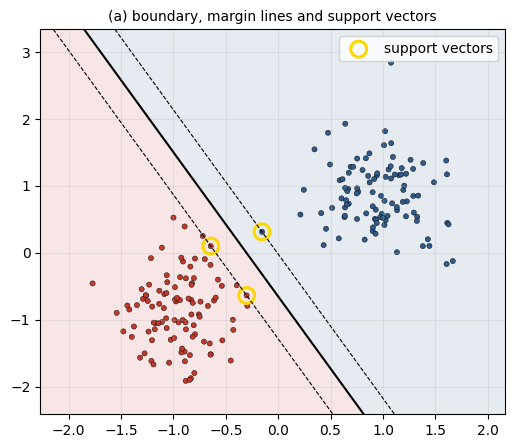

In [12]:
X5, y5 = make_blobs(n_samples=200, centers=[(-2.5, -1.5), (2.5, 1.5)], cluster_std=0.9, random_state=SEED)
y5 = np.where(y5 == 1, 1, -1)
Z5 = StandardScaler().fit_transform(X5)                      # standardized once, then fixed
C5 = 1e4
gx, gy = np.meshgrid(np.linspace(Z5[:, 0].min() - 0.5, Z5[:, 0].max() + 0.5, 60), np.linspace(Z5[:, 1].min() - 0.5, Z5[:, 1].max() + 0.5, 60))
GRID = np.c_[gx.ravel(), gy.ravel()]                         # fixed grid used to compare predictions

def fit5(X, y): return SVC(kernel="linear", C=C5, max_iter=-1).fit(X, y)
base = fit5(Z5, y5); f5 = base.decision_function(Z5); m5 = y5 * f5
sv_idx = base.support_
print("base model: w =", base.coef_[0].round(3), " b =", round(base.intercept_[0], 3), " | margin width =", round(2 / np.linalg.norm(base.coef_), 3))
print("support vectors (indices):", sv_idx.tolist(), "| their margins y*f:", m5[sv_idx].round(3).tolist())
print("points strictly outside the margin (y f > 1.05):", int((m5 > 1.05).sum()), "of", len(y5))

fig, ax = plt.subplots(figsize=(6, 5))
plot_decision(ax, base.decision_function, Z5, y5, "(a) boundary, margin lines and support vectors", pad=0.5)
ax.scatter(Z5[sv_idx, 0], Z5[sv_idx, 1], s=130, facecolors="none", edgecolors="gold", linewidths=2.2, label="support vectors")
ax.legend(); plt.show()


In [13]:
def compare(model, ref, removed=None, label=""):
    # compares a retrained model with the base model; `removed` = original index that was deleted/moved (excluded from SV comparison)
    sv_new = set(model.support_ if removed is None else model.support_)
    return dict(case=label, w1=model.coef_[0][0], w2=model.coef_[0][1], b=model.intercept_[0],
                dw=float(np.linalg.norm(model.coef_[0] - ref.coef_[0])), db=float(abs(model.intercept_[0] - ref.intercept_[0])),
                n_SV=int(model.n_support_.sum()),
                grid_labels_changed=float((model.predict(GRID) != ref.predict(GRID)).mean()))

def drop(i):  # retrain without observation i; map SV indices back to the original numbering
    keep = np.delete(np.arange(len(y5)), i); m = fit5(Z5[keep], y5[keep]); m.orig_support_ = keep[m.support_]; return m

rows = [dict(case="base", w1=base.coef_[0][0], w2=base.coef_[0][1], b=base.intercept_[0], dw=0.0, db=0.0, n_SV=int(base.n_support_.sum()), grid_labels_changed=0.0, SV_set_same=True)]
# (b) remove one observation strictly outside the margin
far = int(np.argsort(m5)[len(m5) // 2])           # a point with a typical (large) margin
mb = drop(far); r = compare(mb, base, label=f"(b) remove NON-support point #{far} (margin {m5[far]:.2f})"); r["SV_set_same"] = set(mb.orig_support_) == set(sv_idx); rows.append(r)
# (c) remove each support vector separately
for i in sv_idx:
    mc = drop(int(i)); r = compare(mc, base, label=f"(c) remove SUPPORT vector #{int(i)} (class {int(y5[i]):+d})")
    r["SV_set_same"] = set(mc.orig_support_) == set(sv_idx) - {int(i)}; rows.append(r)
t5 = pd.DataFrame(rows); print(t5.round(4).to_string(index=False))


                                           case     w1     w2      b     dw     db  n_SV  grid_labels_changed  SV_set_same
                                           base 3.4001 1.5768 1.0303 0.0000 0.0000     3               0.0000         True
(b) remove NON-support point #137 (margin 4.66) 3.4001 1.5768 1.0303 0.0000 0.0000     3               0.0000         True
      (c) remove SUPPORT vector #133 (class -1) 3.3587 1.5830 1.0217 0.0418 0.0087     3               0.0019        False
      (c) remove SUPPORT vector #146 (class -1) 3.4334 1.4999 1.0595 0.0838 0.0291     2               0.0097         True
      (c) remove SUPPORT vector #136 (class +1) 1.8446 0.8938 0.0977 1.6988 0.9327     3               0.0531        False


In [ ]:
# (d) move one support vector progressively toward the opposite class, retraining after each move
sv_pos = [int(i) for i in sv_idx if y5[i] == 1][0]
target = Z5[y5 == -1].mean(0); start = Z5[sv_pos].copy()
rows = []
for t in [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]:
    Zm = Z5.copy(); Zm[sv_pos] = start + t * (target - start)
    mm = fit5(Zm, y5); fm = mm.decision_function(Zm)
    r = dict(step_t=t, moved_point_x=Zm[sv_pos].round(2).tolist(), moved_margin=y5[sv_pos] * fm[sv_pos], moved_point_is_SV=bool(sv_pos in mm.support_),
             moved_pred_correct=bool(mm.predict(Zm[[sv_pos]])[0] == y5[sv_pos]), n_SV=int(mm.n_support_.sum()),
             train_acc=mm.score(Zm, y5), dw=float(np.linalg.norm(mm.coef_[0] - base.coef_[0])), db=float(abs(mm.intercept_[0] - base.intercept_[0])),
             grid_labels_changed=float((mm.predict(GRID) != base.predict(GRID)).mean()), margin_width=2 / np.linalg.norm(mm.coef_))
    rows.append(r)
t5d = pd.DataFrame(rows); print(t5d.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 4, figsize=(17, 4))
for a, t in zip(ax, [0, 0.3, 0.6, 1.0]):
    Zm = Z5.copy(); Zm[sv_pos] = start + t * (target - start); mm = fit5(Zm, y5)
    plot_decision(a, mm.decision_function, Zm, y5, f"moved {int(t*100)}% toward the other class", pad=0.5)
    a.scatter(*Zm[sv_pos], s=170, marker="*", color="gold", edgecolor="k", zorder=5)
plt.tight_layout(); plt.show()


In [14]:
# (f) a tiny degenerate example: three points ON the same two margin lines. Removing one of them leaves the classifier unchanged.
P = np.array([[1.0, 0.0], [1.0, 1.0], [-1.0, 0.0]]); yP = np.array([1, 1, -1])
full = SVC(kernel="linear", C=1e6).fit(P, yP)
print("all three points have margin y*f =", (yP * full.decision_function(P)).round(6).tolist(), "-> all three lie on the margin lines; w =", full.coef_[0].round(4), "b =", round(full.intercept_[0], 4))
for k in range(3):
    keep = [i for i in range(3) if i != k]
    if len(set(yP[keep])) < 2:
        print(f"remove point {k} {P[k]} -> only one class is left, no classifier can be fitted"); continue
    mk = SVC(kernel="linear", C=1e6).fit(P[keep], yP[keep])
    print(f"remove point {k} {P[k]} -> w = {mk.coef_[0].round(4)}, b = {round(mk.intercept_[0], 4)}, unchanged = {bool(np.allclose(mk.coef_[0], full.coef_[0], atol=1e-3) and np.isclose(mk.intercept_[0], full.intercept_[0], atol=1e-3))}")


all three points have margin y*f = [1.0, 1.0, 1.0] -> all three lie on the margin lines; w = [1. 0.] b = -0.0
remove point 0 [1. 0.] -> w = [0.8 0.4], b = -0.2, unchanged = False
remove point 1 [1. 1.] -> w = [1. 0.], b = -0.0, unchanged = True
remove point 2 [-1.  0.] -> only one class is left, no classifier can be fitted


**Interpretation.**

*(a) Base model.* With C = 1e4 the model has 3 support vectors (indices 133, 146, 136), all with a margin of exactly 1, and a margin width of 0.534 in the standardized coordinates. 196 of the 200 points are strictly outside the margin.

*(b) Removing a point outside the margin* (a point with margin 4.66) changes nothing: w, b, the support-vector set and the predictions on the fixed grid are identical (change in w = 0).

*(c) Removing each support vector separately* does change the classifier, by very different amounts: removing #133 shifts w by 0.04 (0.2% of the grid labels change), removing #146 shifts it by 0.08 (1% of grid labels; only two support vectors remain), and removing #136, the only class +1 support vector, shifts w by 1.70 and b by 0.93 and flips 5.3% of the grid labels, because the whole positive side of the margin is then defined by a different point.

*(d) Moving a support vector toward the opposite class.* While the point moves from 0% to 40% of the way, it stays a support vector with margin exactly 1, but it drags the boundary with it: the margin shrinks from 0.534 to 0.046 and the weight vector changes enormously (change in w grows from 1.1 to 39.6). At 50% the point crosses the opposite margin and is misclassified (margin -1.16); the data are no longer separable, the solution jumps to a soft solution (change in w 1.70, training accuracy 0.995, a fourth support vector appears) and then stays **exactly the same** for every further move (50% to 100%). With such a large C the optimum is dominated by the total slack, which is a linear program; its solution sits at a vertex fixed by the other support vectors and does not move while the pull of the moved point keeps pointing the same way.

*(f) Removing a support vector need not change the classifier.* In the three-point example (1,0), (1,1) and (-1,0), all three points lie on the two margin lines, y*f = 1 for each. Removing (1,1) leaves w = (1, 0), b = 0 unchanged, because the remaining two points still determine the same margin. In degenerate configurations like this one (several points on the same margin hyperplane, linearly dependent support vectors) the dual multipliers are not unique and the primal solution is unaffected by dropping one of them. Removing (1,0) does change the classifier (w becomes (0.8, 0.4)), so it depends on which point it is. (Removing (-1,0) leaves only one class, so no classifier exists.)

*(g) Why the effect of moving a point depends on whether it becomes influential after retraining.* A point only affects the boundary through its multiplier alpha. A point outside the margin has alpha = 0, so moving it does nothing until it reaches the margin. Once it reaches the margin it gets a positive alpha and drags the boundary (the first part of (d)). After it has crossed to the wrong side it becomes a bounded support vector (alpha = C), and its influence is through the linear hinge loss, which changes the solution only when the best vertex changes. What matters is therefore the role the point has **after retraining**, not where it was before.

---
## Problem 6: Feature scaling in an industrial sensor classifier

Two features from `make_classification`; the **second feature is multiplied by 10,000** to simulate two sensors with very different units.


In [15]:
X6, y6 = make_classification(n_samples=1000, n_features=2, n_informative=2, n_redundant=0, n_clusters_per_class=1,
                             class_sep=1.2, flip_y=0.02, random_state=SEED)
X6 = X6.copy(); X6[:, 1] *= 10_000
X6_tr, X6_te, y6_tr, y6_te = train_test_split(X6, y6, test_size=0.3, stratify=y6, random_state=SEED)
print("feature std (train):", X6_tr.std(0).round(1), "| ratio:", round(X6_tr.std(0)[1] / X6_tr.std(0)[0]))

# (a)-(c) controlled comparison: IDENTICAL hyperparameters within each kernel type
fixed = {"linear": dict(kernel="linear", C=1.0), "rbf": dict(kernel="rbf", C=1.0, gamma=1.0)}
rows = []; ctrl = {}
for kname, kw in fixed.items():
    for prep in ["unscaled", "standardized"]:
        steps = [StandardScaler()] if prep == "standardized" else []
        t0 = time.time(); mdl = make_pipeline(*steps, SVC(**kw)).fit(X6_tr, y6_tr); fit_s = time.time() - t0; ctrl[(kname, prep)] = mdl
        rows.append(dict(kernel=kname, preprocessing=prep, setting=str(kw), train_acc=mdl.score(X6_tr, y6_tr), test_acc=mdl.score(X6_te, y6_te), n_SV=int(mdl[-1].n_support_.sum()), fit_seconds=fit_s))
t6c = pd.DataFrame(rows); print("CONTROLLED (same hyperparameters):"); print(t6c.round(3).to_string(index=False))


feature std (train): [1.00000e+00 1.36955e+04] | ratio: 13049
CONTROLLED (same hyperparameters):
kernel preprocessing                                   setting  train_acc  test_acc  n_SV  fit_seconds
linear      unscaled            {'kernel': 'linear', 'C': 1.0}      0.930     0.917    70      114.696
linear  standardized            {'kernel': 'linear', 'C': 1.0}      0.934     0.930   142        0.016
   rbf      unscaled {'kernel': 'rbf', 'C': 1.0, 'gamma': 1.0}      1.000     0.520   700        0.020
   rbf  standardized {'kernel': 'rbf', 'C': 1.0, 'gamma': 1.0}      0.957     0.963   122        0.004


In [16]:
# (d) tune each preprocessing-model pipeline separately with 5-fold CV (grids matched to each scale)
cv6 = StratifiedKFold(5, shuffle=True, random_state=SEED)
# note: C = 1 was dropped for the UNSCALED linear grid - a single fit at C = 1 already took about 100 s above (poor conditioning)
grids = {("linear", "unscaled"): {"svc__C": [1e-6, 1e-4, 1e-2]},
         ("linear", "standardized"): {"svc__C": [1e-3, 1e-2, 0.1, 1, 10, 100]},
         ("rbf", "unscaled"): {"svc__C": [1, 10, 100, 1000], "svc__gamma": [1e-10, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-3, 1]},
         ("rbf", "standardized"): {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.01, 0.1, 1, 10]}}
rows = []; tuned6 = {}
for (kname, prep), grid in grids.items():
    steps = [StandardScaler()] if prep == "standardized" else []
    t0 = time.time(); gs = GridSearchCV(make_pipeline(*steps, SVC(kernel=kname)), grid, cv=cv6).fit(X6_tr, y6_tr); search_s = time.time() - t0; tuned6[(kname, prep)] = gs.best_estimator_
    p = gs.predict(X6_te)
    rows.append(dict(kernel=kname, preprocessing=prep, best=str({k.split('__')[1]: v for k, v in gs.best_params_.items()}), cv_acc=gs.best_score_,
                     test_acc=accuracy_score(y6_te, p), test_f1=f1_score(y6_te, p), n_SV=int(gs.best_estimator_[-1].n_support_.sum()), search_seconds=search_s))
t6t = pd.DataFrame(rows); print("TUNED separately:"); print(t6t.round(4).to_string(index=False))


TUNED separately:
kernel preprocessing                     best  cv_acc  test_acc  test_f1  n_SV  search_seconds
linear      unscaled             {'C': 1e-06}  0.9286    0.9200   0.9205   136        102.8619
linear  standardized               {'C': 100}  0.9271    0.9300   0.9298   135          0.1862
   rbf      unscaled {'C': 1, 'gamma': 1e-09}  0.9314    0.9167   0.9175   148          3.1478
   rbf  standardized   {'C': 100, 'gamma': 1}  0.9514    0.9633   0.9627    82          0.5898


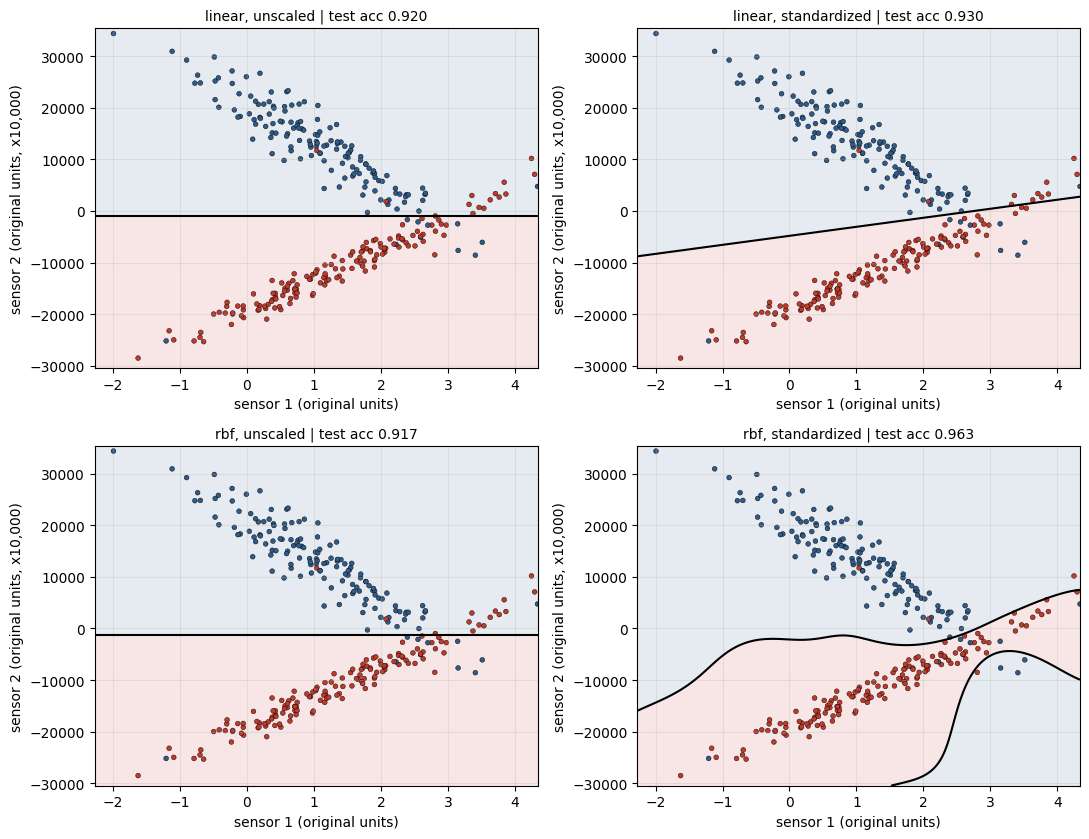

two training points: raw distance = 15460.1; part from sensor 1 = 1.94, from sensor 2 = 15460.1  -> sensor 2 supplies 100.0000% of the squared distance
standardized linear model weights (per standardized feature): [-0.397  2.959]
unscaled linear model weights (per raw unit): [-5.87518836e-06  2.10454602e-04]
the same unscaled weights expressed per standard deviation: [-0.     2.882]

serving the fitted standardized RBF model:
  consistent (training scaler)                       accuracy: 0.963
  WRONG: a new scaler fitted on another batch        accuracy: 0.373
  WRONG: scaler forgotten (raw units sent to model)  accuracy: 0.497
  WRONG: columns swapped before scaling              accuracy: 0.497


In [17]:
# (f) boundaries in the ORIGINAL measurement coordinates (x2 in raw sensor units)
fig, ax = plt.subplots(2, 2, figsize=(11, 8.5))
for a, ((kname, prep), mdl) in zip(ax.ravel(), tuned6.items()):
    lo, hi = X6.min(0), X6.max(0)
    xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], 220), np.linspace(lo[1], hi[1], 220))
    Z = mdl.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    a.contourf(xx, yy, Z > 0, alpha=0.12, colors=[RED, BLUE], levels=[-0.5, 0.5, 1.5]); a.contour(xx, yy, Z, levels=[0], colors="k")
    a.scatter(X6_te[:, 0], X6_te[:, 1], c=np.where(y6_te == 1, BLUE, RED), s=12, edgecolor="k", linewidth=0.3)
    a.set_title(f"{kname}, {prep} | test acc {mdl.score(X6_te, y6_te):.3f}", fontsize=10); a.set_xlabel("sensor 1 (original units)"); a.set_ylabel("sensor 2 (original units, x10,000)")
plt.tight_layout(); plt.show()

# (g) why: RBF distances and the linear regularization geometry
a_, b_ = X6_tr[0], X6_tr[1]
d_raw = np.linalg.norm(a_ - b_); d_feat1 = abs(a_[0] - b_[0]); d_feat2 = abs(a_[1] - b_[1])
print(f"two training points: raw distance = {d_raw:.1f}; part from sensor 1 = {d_feat1:.2f}, from sensor 2 = {d_feat2:.1f}  -> sensor 2 supplies {100 * d_feat2**2 / d_raw**2:.4f}% of the squared distance")
w_std = tuned6[("linear", "standardized")][-1].coef_[0]; sc_ = tuned6[("linear", "standardized")][0]
print("standardized linear model weights (per standardized feature):", w_std.round(3))
w_unscaled = tuned6[("linear", "unscaled")][-1].coef_[0]; print("unscaled linear model weights (per raw unit):", w_unscaled)
print("the same unscaled weights expressed per standard deviation:", (w_unscaled * X6_tr.std(0)).round(3))

# (h) serving a fitted SVM with an inconsistent preprocessing transformation
good = tuned6[("rbf", "standardized")]
sc_fit = good[0]; svm_only = good[-1]
print("\nserving the fitted standardized RBF model:")
print("  consistent (training scaler)                       accuracy:", round(accuracy_score(y6_te, svm_only.predict(sc_fit.transform(X6_te))), 3))
new_scaler = StandardScaler().fit(X6_te + np.array([0.0, 20_000.0]))      # scaler re-fitted on a different (shifted) batch
print("  WRONG: a new scaler fitted on another batch        accuracy:", round(accuracy_score(y6_te, svm_only.predict(new_scaler.transform(X6_te))), 3))
print("  WRONG: scaler forgotten (raw units sent to model)  accuracy:", round(accuracy_score(y6_te, svm_only.predict(X6_te)), 3))
print("  WRONG: columns swapped before scaling              accuracy:", round(accuracy_score(y6_te, svm_only.predict(sc_fit.transform(X6_te[:, ::-1]))), 3))


**Interpretation.**

*(a)-(c) Controlled comparison* (identical hyperparameters). For the **linear** kernel (C = 1) the unscaled and standardized models are similar in accuracy (test 0.917 against 0.930), but the unscaled fit took about **100 seconds** against **0.003 seconds**: the huge numerical range of the second sensor makes the optimization badly conditioned. For the **RBF** kernel (C = 1, gamma = 1) the difference is dramatic: unscaled, the model reaches training accuracy 1.000 but test accuracy **0.520** (every one of the 700 training points becomes a support vector); standardized, it reaches 0.957 training and **0.963 test** with 122 support vectors.

*(d)-(e) Separately tuned pipelines* (5-fold CV):

| kernel | preprocessing | best parameters | CV acc | test acc | support vectors |
|---|---|---|---|---|---|
| linear | unscaled | C = 1e-6 | 0.929 | 0.920 | 136 |
| linear | standardized | C = 100 | 0.927 | 0.930 | 135 |
| RBF | unscaled | C = 1, gamma = 1e-9 | 0.931 | 0.917 | 148 |
| RBF | standardized | C = 100, gamma = 1 | 0.951 | 0.963 | 82 |

With the right parameters the linear models close the gap, but the best C differs by eight orders of magnitude (1e-6 against 100) and the unscaled search took about 90 seconds (the standardized one 0.14 seconds). The unscaled RBF model can only be rescued by an extremely small gamma (1e-9), and even then it stays about 5 points behind the standardized RBF model (0.917 against 0.963).

*(g) Why scaling matters.* The RBF kernel depends only on the squared distance. For two training points the second sensor supplies 100.0000% of the squared distance, so the first sensor is invisible to the kernel and the model effectively uses one feature. For a linear SVM the regularization penalty ||w||^2 is measured in raw units: a feature measured in huge units needs only a tiny weight (about 2e-4 per raw unit for the big sensor) and is almost free under the penalty, while a feature in small units needs a large weight and is penalized more. The tuned unscaled model ends up relying on the large-unit sensor (its weight per standard deviation is 2.88 against about 0 for the other sensor), whereas the standardized model uses both (-0.40 and 2.96). The right C also changes completely when the units change. Standardizing puts all features on the same footing.

*(h) Inconsistent preprocessing at serving time.* The standardized RBF model scores 0.963 when fed with the training scaler. If a **new** scaler is fitted on another (shifted) batch the accuracy falls to **0.373**, if the scaler is forgotten and raw units are sent it falls to **0.497**, and if the columns are swapped before scaling it also falls to 0.497, essentially coin-flip level. Preprocessing and model must be saved and deployed together (for example as one pipeline).

---
## Problem 7: Detect rare manufacturing defects

5,000 observations from `make_classification` (12 features: 6 informative, 2 redundant; class weights [0.97, 0.03]; `flip_y=0.01`; seed 42). Class 1 = defective.


In [18]:
X7, y7 = make_classification(n_samples=5000, n_features=12, n_informative=6, n_redundant=2, weights=[0.97, 0.03], flip_y=0.01, random_state=SEED)
X7_rest, X7_te, y7_rest, y7_te = train_test_split(X7, y7, test_size=0.2, stratify=y7, random_state=SEED)
X7_tr, X7_va, y7_tr, y7_va = train_test_split(X7_rest, y7_rest, test_size=0.25, stratify=y7_rest, random_state=SEED)
print("sizes:", len(y7_tr), len(y7_va), len(y7_te), "| defects (train/val/test):", int(y7_tr.sum()), int(y7_va.sum()), int(y7_te.sum()))

# (b) always-normal baseline
base_pred = np.zeros_like(y7_va)
print("ALWAYS-NORMAL baseline on validation: accuracy =", round(accuracy_score(y7_va, base_pred), 4), "| defect recall =", recall_score(y7_va, base_pred), "| defects caught: 0 of", int(y7_va.sum()))


sizes: 3000 1000 1000 | defects (train/val/test): 104 34 35
ALWAYS-NORMAL baseline on validation: accuracy = 0.966 | defect recall = 0.0 | defects caught: 0 of 34


In [19]:
# (c)+(d) fixed kernel (RBF) and fixed C = 1; only the class weights change
weights = {"unweighted": None, "balanced": "balanced", "weight 5": {0: 1, 1: 5}, "weight 10": {0: 1, 1: 10}, "weight 25": {0: 1, 1: 25}, "weight 50": {0: 1, 1: 50}}
models7, rows, scores7 = {}, [], {}
for name, cw in weights.items():
    mdl = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale", class_weight=cw)).fit(X7_tr, y7_tr); models7[name] = mdl
    s = mdl.decision_function(X7_va); scores7[name] = s; p = (s >= 0).astype(int); tn, fp, fn, tp = confusion_matrix(y7_va, p).ravel()
    rows.append(dict(model=name, accuracy=accuracy_score(y7_va, p), defect_precision=precision_score(y7_va, p, zero_division=0), defect_recall=recall_score(y7_va, p),
                     F1=f1_score(y7_va, p), avg_precision=average_precision_score(y7_va, s), TN=tn, FP=fp, FN=fn, TP=tp, flagged_pct=100 * p.mean()))
t7 = pd.DataFrame(rows); print(t7.round(3).to_string(index=False))


     model  accuracy  defect_precision  defect_recall    F1  avg_precision  TN  FP  FN  TP  flagged_pct
unweighted     0.973             1.000          0.206 0.341          0.591 966   0  27   7          0.7
  balanced     0.926             0.273          0.706 0.393          0.443 902  64  10  24          8.8
  weight 5     0.978             0.750          0.529 0.621          0.646 960   6  16  18          2.4
 weight 10     0.972             0.594          0.559 0.576          0.573 953  13  15  19          3.2
 weight 25     0.946             0.344          0.647 0.449          0.456 924  42  12  22          6.4
 weight 50     0.939             0.310          0.647 0.419          0.430 917  49  12  22          7.1


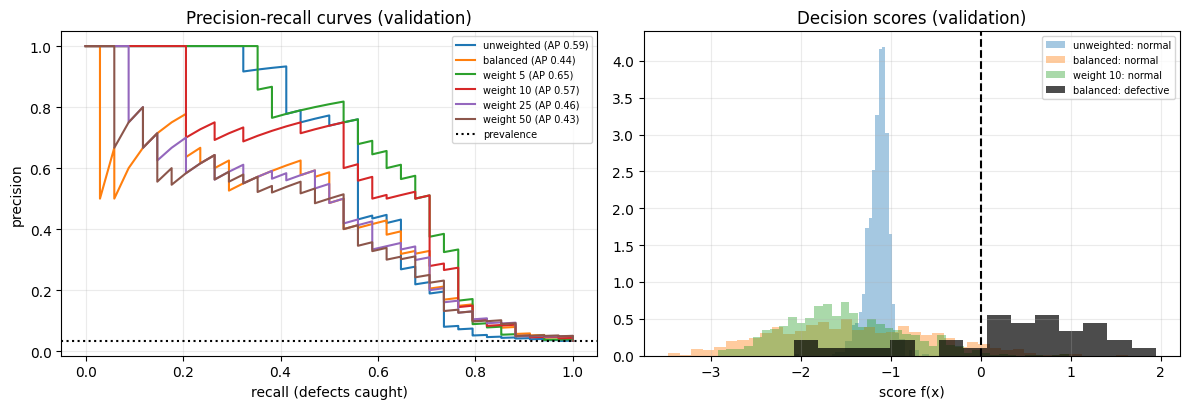

In [20]:
# (f) precision-recall curves from the decision scores
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for name, s in scores7.items():
    pr, rc, _ = precision_recall_curve(y7_va, s); ax[0].plot(rc, pr, label=f"{name} (AP {average_precision_score(y7_va, s):.2f})")
ax[0].axhline(y7_va.mean(), color="k", ls=":", label="prevalence"); ax[0].set_xlabel("recall (defects caught)"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision-recall curves (validation)"); ax[0].legend(fontsize=7)
for name in ["unweighted", "balanced", "weight 10"]:
    ax[1].hist(scores7[name][y7_va == 0], bins=40, alpha=0.4, label=f"{name}: normal", density=True)
ax[1].hist(scores7["balanced"][y7_va == 1], bins=15, alpha=0.7, color="k", label="balanced: defective", density=True)
ax[1].axvline(0, color="k", ls="--"); ax[1].set_title("Decision scores (validation)"); ax[1].set_xlabel("score f(x)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()


In [21]:
# (g) operational objective: "catch as many defects as possible, but keep defect precision at or above 40%
#     (so at most about 1.5 normal items are inspected for every defect found)".  Selection uses VALIDATION data only.
PREC_FLOOR = 0.40
ok = t7[t7.defect_precision >= PREC_FLOOR]
sel7 = ok.sort_values(["defect_recall", "defect_precision"], ascending=False).iloc[0].model if len(ok) else t7.sort_values("F1", ascending=False).iloc[0].model
print("candidates meeting the precision floor:", ok.model.tolist(), "| selected:", sel7)
final7 = models7[sel7]
s_te = final7.decision_function(X7_te); p_te = (s_te >= 0).astype(int); tn, fp, fn, tp = confusion_matrix(y7_te, p_te).ravel()
print("TEST (selected model, default threshold 0):", dict(accuracy=round(accuracy_score(y7_te, p_te), 4), precision=round(precision_score(y7_te, p_te, zero_division=0), 3),
      recall=round(recall_score(y7_te, p_te), 3), F1=round(f1_score(y7_te, p_te), 3), AP=round(average_precision_score(y7_te, s_te), 3)), "| [TN FP FN TP] =", [int(tn), int(fp), int(fn), int(tp)])
print("test always-normal baseline accuracy:", round(1 - y7_te.mean(), 4))


candidates meeting the precision floor: ['unweighted', 'weight 5', 'weight 10'] | selected: weight 10
TEST (selected model, default threshold 0): {'accuracy': 0.965, 'precision': np.float64(0.5), 'recall': np.float64(0.571), 'F1': np.float64(0.533), 'AP': np.float64(0.565)} | [TN FP FN TP] = [945, 20, 15, 20]
test always-normal baseline accuracy: 0.965


**Interpretation.**

*(b) Baseline.* Predicting "normal" for everything gives a validation accuracy of 0.966 and catches 0 of the 34 defects (the test set: accuracy 0.965, 35 defects).

*(c)-(e) Class weighting* (RBF kernel, C = 1 fixed; validation set, 34 defects):

| model | accuracy | defect precision | defect recall | F1 | avg precision | flagged |
|---|---|---|---|---|---|---|
| unweighted | 0.973 | 1.000 | 0.206 | 0.341 | 0.591 | 0.7% |
| balanced | 0.926 | 0.273 | 0.706 | 0.393 | 0.443 | 8.8% |
| weight 5 | 0.978 | 0.750 | 0.529 | 0.621 | 0.646 | 2.4% |
| weight 10 | 0.972 | 0.594 | 0.559 | 0.576 | 0.573 | 3.2% |
| weight 25 | 0.946 | 0.344 | 0.647 | 0.449 | 0.456 | 6.4% |
| weight 50 | 0.939 | 0.310 | 0.647 | 0.419 | 0.430 | 7.1% |

Heavier weights buy recall at the cost of precision and more flagged items, as expected. The unweighted model is the extreme example: it is 100% precise on the 7 defects it flags but misses 27 of 34.

*(g) Stated operational objective:* "catch as many defects as possible while keeping defect precision at or above 40%" (so at most about 1.5 normal items inspected for each defect found). Three models meet the precision floor (unweighted, weight 5, weight 10); the highest recall among them is **weight 10** (recall 0.559). On the test set at the default threshold it gives precision 0.50, recall 0.571 (20 of 35 defects), F1 0.533 and average precision 0.565 (confusion matrix: 945 true normal, 20 false alarms, 15 missed, 20 caught).

*(h) Why accuracy can favour a detector that misses most defects.* Defects are only about 3% of the items, so a model that ignores them is right 96.5% to 97% of the time. The unweighted model has a higher accuracy (0.973) than the balanced model (0.926) yet catches only 7 of 34 defects, while the balanced model catches 24 of 34 but is penalized by accuracy for its false alarms. Accuracy gives each of the 966 normal items the same weight as a defect that costs 50 times more to miss; precision, recall, average precision and costs are the right measures.

---
## Problem 8: Choose a threshold under inspection constraints

The classifier from Problem 7 is **not retrained**. Costs: missed defect = 500, unnecessary inspection = 10; at most 8% of items can be flagged.


In [22]:
CM, CFP, MAX_FLAG = 500, 10, 0.08
s_va = final7.decision_function(X7_va)                    # (a) validation decision scores
cands = np.unique(np.r_[np.quantile(s_va, np.linspace(0, 1, 801)), 0.0])      # (b) candidate thresholds (t = 0 included)
def evaluate(scores, y, t):
    pred = scores >= t; fn = int(((~pred) & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
    return dict(t=t, FN=fn, FP=fp, cost=CM * fn + CFP * fp, flagged=float(pred.mean()), recall=float(pred[y == 1].mean()), precision=float(y[pred].mean()) if pred.any() else np.nan)
va_tab = pd.DataFrame([evaluate(s_va, y7_va, t) for t in cands])                  # (c) cost and (d) fraction flagged
feasible = va_tab[va_tab.flagged <= MAX_FLAG]
best_t = feasible.sort_values(["cost", "flagged"]).iloc[0]                         # (e) min-cost threshold meeting the constraint
default = va_tab.iloc[(va_tab.t - 0.0).abs().argmin()]
unc = va_tab.sort_values("cost").iloc[0]
cmp = pd.DataFrame([default, best_t, unc], index=["(f) default t = 0", "selected (min cost, flagged <= 8%)", "unconstrained min cost"])
print(cmp.round(3).to_string())


                                        t    FN    FP    cost  flagged  recall  precision
(f) default t = 0                   0.000  15.0  13.0  7630.0    0.032   0.559      0.594
selected (min cost, flagged <= 8%) -0.194  10.0  23.0  5230.0    0.047   0.706      0.511
unconstrained min cost             -0.472   8.0  69.0  4690.0    0.095   0.765      0.274


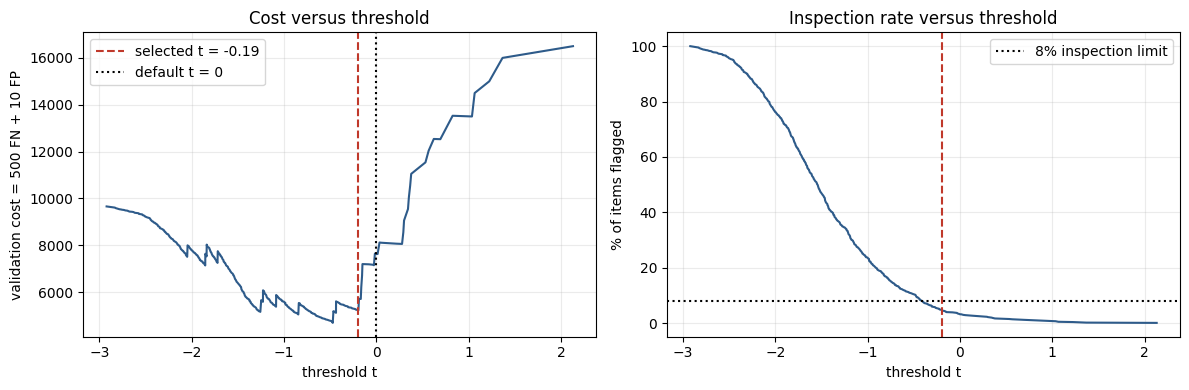

TEST, selected threshold : {'t': np.float64(-0.194), 'FN': 15, 'FP': 32, 'cost': 7820, 'flagged': 0.052, 'recall': 0.571, 'precision': 0.385}
TEST, default threshold  : {'t': 0.0, 'FN': 15, 'FP': 20, 'cost': 7700, 'flagged': 0.04, 'recall': 0.571, 'precision': 0.5}
does the inspection constraint (<= 8%) still hold on the test set? True (flagged 5.20% vs limit 8%)
sampling variation of the flagged fraction at the fixed threshold (2000 resamples of test size): 5th-95th percentile = 3.60% to 5.80%
share of resamples that exceed the 8% limit: 0.00%


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(va_tab.t, va_tab.cost, color=BLUE); ax[0].axvline(best_t.t, color=RED, ls="--", label=f"selected t = {best_t.t:.2f}"); ax[0].axvline(0, color="k", ls=":", label="default t = 0")
ax[0].set_xlabel("threshold t"); ax[0].set_ylabel("validation cost = 500 FN + 10 FP"); ax[0].legend(); ax[0].set_title("Cost versus threshold")
ax[1].plot(va_tab.t, 100 * va_tab.flagged, color=BLUE); ax[1].axhline(100 * MAX_FLAG, color="k", ls=":", label="8% inspection limit"); ax[1].axvline(best_t.t, color=RED, ls="--")
ax[1].set_xlabel("threshold t"); ax[1].set_ylabel("% of items flagged"); ax[1].legend(); ax[1].set_title("Inspection rate versus threshold")
plt.tight_layout(); plt.show()

# (g)+(h) apply the validation threshold UNCHANGED to the test set
s_te = final7.decision_function(X7_te)
te_sel = evaluate(s_te, y7_te, best_t.t); te_def = evaluate(s_te, y7_te, 0.0)
print("TEST, selected threshold :", {k: round(v, 3) for k, v in te_sel.items()})
print("TEST, default threshold  :", {k: round(v, 3) for k, v in te_def.items()})
print("does the inspection constraint (<= 8%) still hold on the test set?", te_sel["flagged"] <= MAX_FLAG, f"(flagged {100 * te_sel['flagged']:.2f}% vs limit {100 * MAX_FLAG:.0f}%)")
# how much would the flagged fraction vary from sample to sample? bootstrap the validation threshold on test-sized samples
rng_b = np.random.default_rng(SEED); fr = [ (rng_b.choice(s_va, size=len(y7_te)) >= best_t.t).mean() for _ in range(2000)]
print(f"sampling variation of the flagged fraction at the fixed threshold (2000 resamples of test size): 5th-95th percentile = {100*np.percentile(fr,5):.2f}% to {100*np.percentile(fr,95):.2f}%")
print(f"share of resamples that exceed the 8% limit: {np.mean(np.array(fr) > MAX_FLAG):.2%}")


**Interpretation.**

Using the validation decision scores of the (non-retrained) weight-10 classifier, with a missed defect costing 500, an inspection 10 and at most 8% of items flagged:

| threshold | missed (FN) | false alarms (FP) | validation cost | flagged | recall | precision |
|---|---|---|---|---|---|---|
| default t = 0 | 15 | 13 | 7,630 | 3.2% | 0.559 | 0.594 |
| **selected t = -0.194** (min cost, flagged <= 8%) | 10 | 23 | **5,230** | 4.7% | 0.706 | 0.511 |
| unconstrained minimum t = -0.472 | 8 | 69 | 4,690 | 9.5% | 0.765 | 0.274 |

The unconstrained minimum would flag 9.5% of the items, more than the 8% limit, so the constraint is what picks the final threshold. Lowering the threshold from 0 to -0.194 cuts the validation cost from 7,630 to 5,230 by catching 5 more defects for 10 more false alarms: one missed defect (500) is as expensive as 50 unnecessary inspections.

*(g)-(h) Test set.* Applied unchanged to the test set, the selected threshold flags **5.2%** of the items, so the 8% limit still holds. But the cost did **not** improve: it was 7,820 (15 missed defects and 32 false alarms) against 7,700 for the default threshold (15 missed, 20 false alarms). With only 34 validation defects and 35 test defects, a difference of a single defect (500 units) swamps everything, so the validation gain was mostly noise.

*Why the constraint is not guaranteed on new data.* The 8% limit was checked on the validation sample. On a different sample the fraction of items above the threshold changes because of sampling variation (the number of defects, and how many normal items have high scores, are random) and, in real life, because the process drifts. A bootstrap of the validation scores to test-sized samples shows the flagged fraction at this fixed threshold ranges from about **3.6% to 5.8%** (5th to 95th percentile) and exceeds 8% in 0% of the resamples here, but that only covers sampling noise, not drift. The safe approach is to keep a safety margin below the limit and to monitor the inspection rate in production.

---
## Problem 9: Decision scores versus calibrated probabilities

An imbalanced binary dataset (6,000 observations, about 10% positives) split into **model-training (50%)**, **calibration (25%)** and **test (25%)** partitions.


In [24]:
X9, y9 = make_classification(n_samples=6000, n_features=10, n_informative=5, n_redundant=2, weights=[0.9, 0.1], flip_y=0.03, class_sep=0.8, random_state=SEED)
X9_a, X9_te, y9_a, y9_te = train_test_split(X9, y9, test_size=0.25, stratify=y9, random_state=SEED)
X9_tr, X9_cal, y9_tr, y9_cal = train_test_split(X9_a, y9_a, test_size=1 / 3, stratify=y9_a, random_state=SEED)
print("sizes model-train / calibration / test:", len(y9_tr), len(y9_cal), len(y9_te), "| positive rates:", round(y9_tr.mean(), 3), round(y9_cal.mean(), 3), round(y9_te.mean(), 3))

# (a) standardized SVM fitted ONLY on the model-training partition
svm9 = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")).fit(X9_tr, y9_tr)
# (b)+(c) sigmoid (Platt) calibration: logistic regression on the calibration scores
f_cal = svm9.decision_function(X9_cal).reshape(-1, 1)
platt = LogisticRegression(C=1e6).fit(f_cal, y9_cal)
print("Platt model: p = sigmoid(%.3f * f + %.3f)" % (platt.coef_[0][0], platt.intercept_[0]))

# (d) compare on the test partition
f_te = svm9.decision_function(X9_te)
p_cal = platt.predict_proba(f_te.reshape(-1, 1))[:, 1]       # calibrated probability
p_sig = 1.0 / (1.0 + np.exp(-f_te))                          # (f) sigmoid(f) used as an UNcalibrated probability
rows = []
for name, p in [("calibrated (Platt on calibration split)", p_cal), ("uncalibrated sigmoid(f)", p_sig)]:
    rows.append(dict(estimate=name, brier=brier_score_loss(y9_te, p), log_loss=log_loss(y9_te, p), mean_predicted=p.mean(), actual_rate=y9_te.mean(),
                     acc_at_0_5=accuracy_score(y9_te, (p >= 0.5).astype(int)), recall_at_0_5=recall_score(y9_te, (p >= 0.5).astype(int)), ROC_AUC=roc_auc_score(y9_te, p), avg_precision=average_precision_score(y9_te, p)))
rows.append(dict(estimate="raw decision score f (threshold 0)", brier=np.nan, log_loss=np.nan, mean_predicted=np.nan, actual_rate=y9_te.mean(),
                 acc_at_0_5=accuracy_score(y9_te, (f_te >= 0).astype(int)), recall_at_0_5=recall_score(y9_te, (f_te >= 0).astype(int)), ROC_AUC=roc_auc_score(y9_te, f_te), avg_precision=average_precision_score(y9_te, f_te)))
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("always predicting the base rate:  Brier =", round(brier_score_loss(y9_te, np.full(len(y9_te), y9_tr.mean())), 4), "| log loss =", round(log_loss(y9_te, np.full(len(y9_te), y9_tr.mean())), 4))


sizes model-train / calibration / test: 3000 1500 1500 | positive rates: 0.11 0.111 0.11
Platt model: p = sigmoid(4.719 * f + 2.462)
                               estimate  brier  log_loss  mean_predicted  actual_rate  acc_at_0_5  recall_at_0_5  ROC_AUC  avg_precision
calibrated (Platt on calibration split) 0.0524    0.1984          0.1157         0.11      0.9360         0.5515   0.8984         0.7245
                uncalibrated sigmoid(f) 0.0856    0.3298          0.2533         0.11      0.9267         0.3636   0.8984         0.7245
     raw decision score f (threshold 0)    NaN       NaN             NaN         0.11      0.9267         0.3636   0.8984         0.7245
always predicting the base rate:  Brier = 0.0979 | log loss = 0.3465


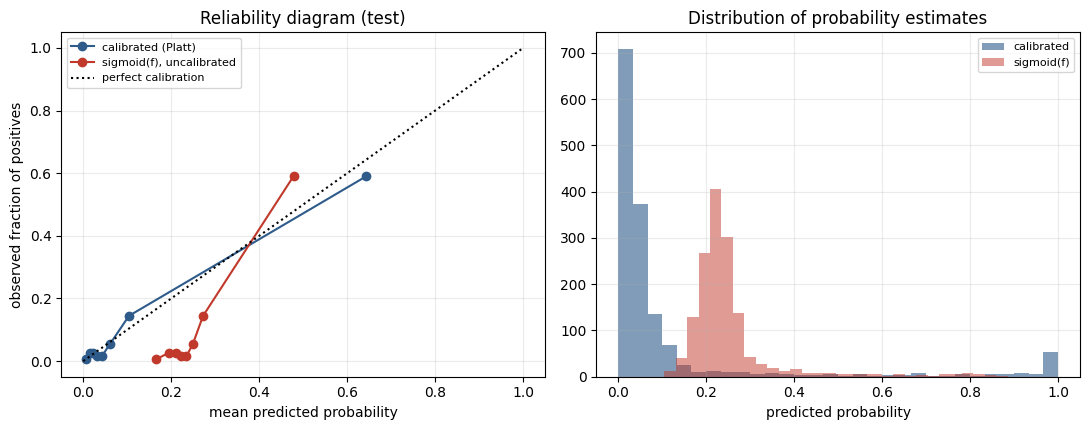

Spearman rank correlation between f and calibrated p: 1.0
ROC AUC raw f / calibrated p / sigmoid(f): 0.898382 0.898382 0.898382


In [25]:
# (e) reliability diagram (test partition)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for name, p, c in [("calibrated (Platt)", p_cal, BLUE), ("sigmoid(f), uncalibrated", p_sig, RED)]:
    frac, mean_p = calibration_curve(y9_te, p, n_bins=8, strategy="quantile"); ax[0].plot(mean_p, frac, "o-", color=c, label=name)
ax[0].plot([0, 1], [0, 1], "k:", label="perfect calibration"); ax[0].set_xlabel("mean predicted probability"); ax[0].set_ylabel("observed fraction of positives"); ax[0].set_title("Reliability diagram (test)"); ax[0].legend(fontsize=8)
ax[1].hist(p_cal, bins=30, alpha=0.6, color=BLUE, label="calibrated"); ax[1].hist(p_sig, bins=30, alpha=0.5, color=RED, label="sigmoid(f)"); ax[1].set_xlabel("predicted probability"); ax[1].set_title("Distribution of probability estimates"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
# (g) ranking: identical for any increasing transformation of f
print("Spearman rank correlation between f and calibrated p:", round(float(pd.Series(f_te).corr(pd.Series(p_cal), method="spearman")), 6))
print("ROC AUC raw f / calibrated p / sigmoid(f):", round(roc_auc_score(y9_te, f_te), 6), round(roc_auc_score(y9_te, p_cal), 6), round(roc_auc_score(y9_te, p_sig), 6))


**Interpretation.**

Platt scaling fitted on the calibration split gave p = sigmoid(4.72 f + 2.46). Results on the test partition (base rate 11%):

| estimate | Brier | log loss | mean predicted probability | accuracy at 0.5 | recall at 0.5 | ROC AUC | avg precision |
|---|---|---|---|---|---|---|---|
| calibrated (Platt) | **0.0524** | **0.1984** | 0.116 | 0.936 | 0.552 | 0.8984 | 0.7245 |
| sigmoid(f), uncalibrated | 0.0856 | 0.3298 | 0.253 | 0.927 | 0.364 | 0.8984 | 0.7245 |

Always predicting the 11% base rate gives a Brier score of 0.098, so the uncalibrated sigmoid(f) (0.086) is barely better than saying nothing, while the calibrated probabilities (0.052) are a large improvement. The reliability diagram shows why: sigmoid(f) overestimates the risk (its mean prediction is 25% against a real 11%), whereas the calibrated probabilities lie close to the diagonal.

*(g)-(h) Ranking versus calibration.* The ROC AUC (0.8984) and the average precision (0.7245) are **identical** for the raw score f, the calibrated probability and sigmoid(f): the Spearman rank correlation between f and p is 1.0. Both mappings are increasing functions of f, so they put the observations in exactly the same order, and AUC and AP only depend on the order. Calibration therefore improved the probability metrics a lot without changing the ranking at all. Classification accuracy changes only because a probability threshold of 0.5 corresponds to a different score threshold than f = 0 (it catches more positives: recall 0.552 against 0.364, with a slightly higher accuracy here), not because the model separates the classes better. Improved calibration need not mean improved ranking or better accuracy: the three things measure different properties (how honest the numbers are, how well the items are ordered, and where the cut is made).

---
## Problem 10: One-class SVM for machine anomaly detection

Training data: 1,000 "normal operation" points from N((0, 0), I). Validation and test sets are independent mixtures of known normal operation, **fault** observations from N((4, 4), 0.5 I) and an **unseen safe regime** from N((-4, 0), 0.5 I). Only faults are real anomalies; both normal regimes are safe.


In [26]:
def make_mixture(seed, n_norm=500, n_fault=100, n_unseen=200):
    r = np.random.default_rng(seed)
    Xn = r.multivariate_normal([0, 0], np.eye(2), n_norm)
    Xf = r.multivariate_normal([4, 4], 0.5 * np.eye(2), n_fault)
    Xu = r.multivariate_normal([-4, 0], 0.5 * np.eye(2), n_unseen)
    X = np.vstack([Xn, Xf, Xu]); g = np.r_[np.zeros(n_norm), np.ones(n_fault), 2 * np.ones(n_unseen)].astype(int)   # 0 normal, 1 fault, 2 unseen safe
    return X, g
rng10 = np.random.default_rng(SEED)
X10_tr = rng10.multivariate_normal([0, 0], np.eye(2), 1000)
X10_va, g_va = make_mixture(1); X10_te, g_te = make_mixture(2)
sc10 = StandardScaler().fit(X10_tr)                                          # (a) scaler fitted on training normal data only

def evaluate10(model, X, g):
    rej = model.predict(sc10.transform(X)) == -1                              # -1 = "outside the learned normal region" = alarm
    return dict(fault_recall=rej[g == 1].mean(), false_alarm_known_normal=rej[g == 0].mean(), false_alarm_unseen_safe=rej[g == 2].mean())

rows = []; grid10 = {}
for nu in [0.01, 0.05, 0.1, 0.2]:
    for gamma in [0.05, 0.2, 1.0, 5.0]:                                       # (b) several nu and gamma values
        m = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(sc10.transform(X10_tr)); grid10[(nu, gamma)] = m
        r = evaluate10(m, X10_va, g_va); r.update(nu=nu, gamma=gamma, train_rejected=float((m.predict(sc10.transform(X10_tr)) == -1).mean()), n_SV=len(m.support_)); rows.append(r)
t10 = pd.DataFrame(rows)[["nu", "gamma", "train_rejected", "n_SV", "fault_recall", "false_alarm_known_normal", "false_alarm_unseen_safe"]]
print(t10.round(3).to_string(index=False))


  nu  gamma  train_rejected  n_SV  fault_recall  false_alarm_known_normal  false_alarm_unseen_safe
0.01   0.05           0.010    13           1.0                     0.016                    0.920
0.01   0.20           0.008    13           1.0                     0.018                    0.915
0.01   1.00           0.095   111           1.0                     0.100                    0.950
0.01   5.00           0.399   305           1.0                     0.430                    0.970
0.05   0.05           0.050    52           1.0                     0.052                    0.980
0.05   0.20           0.051    55           1.0                     0.052                    0.980
0.05   1.00           0.091   122           1.0                     0.090                    0.980
0.05   5.00           0.339   408           1.0                     0.366                    0.970
0.10   0.05           0.099   101           1.0                     0.076                    0.990
0.10   0.2

configurations meeting 10% false alarms on both safe regimes: 0
selected (nu, gamma) = (np.float64(0.01), np.float64(0.2))
TEST: {'fault_recall': np.float64(1.0), 'false_alarm_known_normal': np.float64(0.018), 'false_alarm_unseen_safe': np.float64(0.94)}


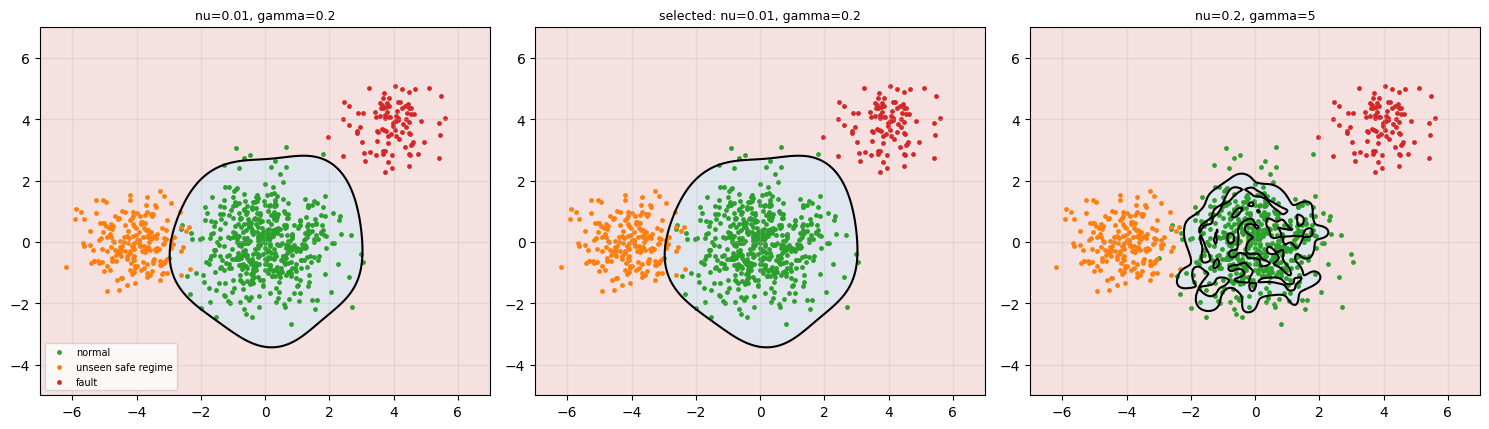

In [27]:
# (e) select on VALIDATION data: highest fault recall among configurations with a false-alarm rate <= 10% on EACH safe regime;
#     if no configuration qualifies, take the one with the smallest worst-regime false-alarm rate that still has fault recall >= 0.9
ok = t10[(t10.false_alarm_known_normal <= 0.10) & (t10.false_alarm_unseen_safe <= 0.10)]
print("configurations meeting 10% false alarms on both safe regimes:", len(ok))
t10["worst_false_alarm"] = t10[["false_alarm_known_normal", "false_alarm_unseen_safe"]].max(axis=1)
if len(ok): sel = ok.sort_values("fault_recall", ascending=False).iloc[0]
else:       sel = t10[t10.fault_recall >= 0.9].sort_values("worst_false_alarm").iloc[0]
print("selected (nu, gamma) =", (sel.nu, sel.gamma)); m_sel = grid10[(sel.nu, sel.gamma)]
print("TEST:", {k: round(v, 3) for k, v in evaluate10(m_sel, X10_te, g_te).items()})

# (d) acceptance regions
def region(ax, model, title, Xtrain=None):
    xx, yy = np.meshgrid(np.linspace(-7, 7, 280), np.linspace(-5, 7, 280)); P = np.c_[xx.ravel(), yy.ravel()]
    Z = model.decision_function(sc10.transform(P)).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, alpha=0.15, colors=[RED, BLUE], levels=[-0.5, 0.5, 1.5]); ax.contour(xx, yy, Z, levels=[0], colors="k")
    ax.scatter(*X10_te[g_te == 0].T, s=6, c="tab:green", label="normal"); ax.scatter(*X10_te[g_te == 2].T, s=6, c="tab:orange", label="unseen safe regime"); ax.scatter(*X10_te[g_te == 1].T, s=6, c="tab:red", label="fault")
    ax.set_title(title, fontsize=9); ax.set_xlim(-7, 7); ax.set_ylim(-5, 7)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
region(ax[0], grid10[(0.01, 0.2)], "nu=0.01, gamma=0.2"); region(ax[1], m_sel, f"selected: nu={sel.nu}, gamma={sel.gamma}"); region(ax[2], grid10[(0.2, 5.0)], "nu=0.2, gamma=5")
ax[0].legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()


                                                                setup  fault_recall  false_alarm_known_normal  false_alarm_unseen_safe
                                               original training data           1.0                     0.018                    0.940
          + 150 unseen-regime observations (retrained, same nu/gamma)           1.0                     0.020                    0.035
+ unseen regime, (nu, gamma) re-selected on validation = (0.01, 0.05)           1.0                     0.008                    0.045


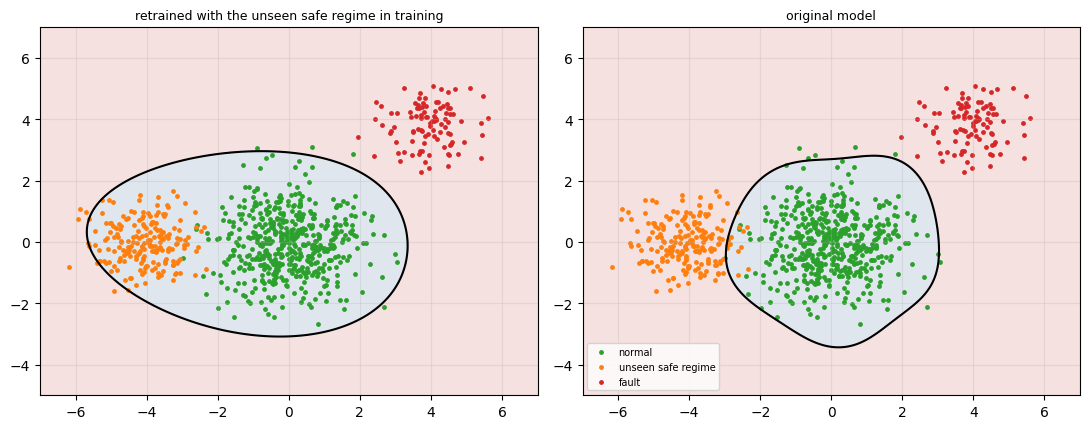

In [28]:
# (f)+(g) add representative observations of the unseen SAFE regime to the normal training data, retrain, evaluate on untouched test data
r2 = np.random.default_rng(SEED + 7); X_extra = r2.multivariate_normal([-4, 0], 0.5 * np.eye(2), 150)
X10_tr2 = np.vstack([X10_tr, X_extra]); sc10b = StandardScaler().fit(X10_tr2)
def evaluate10b(model, scaler, X, g):
    rej = model.predict(scaler.transform(X)) == -1
    return dict(fault_recall=rej[g == 1].mean(), false_alarm_known_normal=rej[g == 0].mean(), false_alarm_unseen_safe=rej[g == 2].mean())
rows = []
for label, mdl, scl in [("original training data", m_sel, sc10)]:
    rows.append(dict(setup=label, **evaluate10b(mdl, scl, X10_te, g_te)))
m_aug = OneClassSVM(kernel="rbf", nu=sel.nu, gamma=sel.gamma).fit(sc10b.transform(X10_tr2))
rows.append(dict(setup="+ 150 unseen-regime observations (retrained, same nu/gamma)", **evaluate10b(m_aug, sc10b, X10_te, g_te)))
# gamma re-selected on the validation set for the augmented data (the scaler changed, so the same gamma means a different scale)
best = None
for nu in [0.01, 0.05, 0.1]:
    for gamma in [0.05, 0.2, 1.0]:
        m_ = OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(sc10b.transform(X10_tr2)); v = evaluate10b(m_, sc10b, X10_va, g_va)
        if v["false_alarm_known_normal"] <= 0.1 and v["false_alarm_unseen_safe"] <= 0.1 and (best is None or v["fault_recall"] > best[0]): best = (v["fault_recall"], nu, gamma, m_)
if best: rows.append(dict(setup=f"+ unseen regime, (nu, gamma) re-selected on validation = ({best[1]}, {best[2]})", **evaluate10b(best[3], sc10b, X10_te, g_te)))
print(pd.DataFrame(rows).round(3).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
sc_backup = sc10; sc10 = sc10b; region(ax[0], m_aug if not best else best[3], "retrained with the unseen safe regime in training"); sc10 = sc_backup
region(ax[1], m_sel, "original model"); ax[1].legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()


In [29]:
# (i) contamination: 5% of the 'normal' training data are actually fault observations
r3 = np.random.default_rng(SEED + 11); n_c = 50
X10_cont = np.vstack([X10_tr[:950], r3.multivariate_normal([4, 4], 0.5 * np.eye(2), n_c)])
sc10c = StandardScaler().fit(X10_cont)
rows = []
for nu in [0.01, 0.05, 0.1]:
    for label, Xt, scl in [("clean", X10_tr, sc10), ("5% faults in training", X10_cont, sc10c)]:
        m_ = OneClassSVM(kernel="rbf", nu=nu, gamma=0.2).fit(scl.transform(Xt)); rows.append(dict(nu=nu, training=label, **evaluate10b(m_, scl, X10_te, g_te)))
print(pd.DataFrame(rows).round(3).to_string(index=False))


  nu              training  fault_recall  false_alarm_known_normal  false_alarm_unseen_safe
0.01                 clean          1.00                     0.018                    0.940
0.01 5% faults in training          0.03                     0.018                    0.935
0.05                 clean          1.00                     0.052                    0.995
0.05 5% faults in training          0.21                     0.052                    0.995
0.10                 clean          1.00                     0.098                    1.000
0.10 5% faults in training          0.47                     0.074                    0.995


**Interpretation.**

*(c) Regime-specific metrics.* In all 16 (nu, gamma) combinations the fault recall is 1.0: the faults, centred at (4, 4), are far from the training cloud. The false-alarm rate on the **known** normal regime is close to nu for the smaller gammas (0.016 at nu = 0.01 up to 0.19 at nu = 0.2) and much higher, 0.35 to 0.43, with the very local gamma = 5. The false-alarm rate on the **unseen safe regime** is 91.5% to 99.5% in every configuration: the model treats everything it has not seen as anomalous.

*(e) Selection.* No configuration reaches 10% false alarms on both safe regimes, so the selection rule falls back to the smallest worst-regime false-alarm rate with fault recall at least 0.9: nu = 0.01, gamma = 0.2. On the untouched test set it gives fault recall 1.0, 1.8% false alarms on known normal operation and **94%** false alarms on the unseen safe regime.

*(f)-(g) Adding the unseen regime.* After adding 150 observations from the unseen safe regime to the normal training data and retraining with the same settings, the test false-alarm rate on that regime falls from 94% to **3.5%**, with fault recall still 1.0 and known-normal false alarms 2.0% (a re-selected nu = 0.01, gamma = 0.05 gives 0.8% and 4.5%). The detector only knows what it has been shown.

*(h) Novelty detection versus fault detection.* A one-class SVM is a **novelty detector**: it learns the region where the training data live and flags anything outside it. A **fault detector** needs to say whether a state is actually dangerous. Novel is not the same as faulty: the unseen safe regime is new but harmless, and the one-class model rejects it 94% of the time. Fault detection needs labelled faults, domain knowledge about which regimes are safe, or training data that cover all safe regimes.

*(i) Contamination.* With 5% of the "normal" training data actually faults, the fault recall collapses: from 1.00 to **0.03** at nu = 0.01, **0.21** at nu = 0.05 and **0.47** at nu = 0.1, while the false-alarm rates on normal data are unchanged. The model has learned the fault pattern as part of normal operation and accepts it; a larger nu (which allows more training points to be outliers) hides part of this problem but also raises false alarms. Training data for a one-class model must be cleaned.

---
## Problem 11: SVR: tolerance, fit and sparsity

400 observations: x ~ Uniform(0, 10), y = sin(x) + 0.2x + noise (sd 0.15). Train / validation / test = 60 / 20 / 20. Inputs are standardized, the target stays in its original units.


 eps    C  n_SV  SV_share  val_MAE  val_RMSE  train_eps_loss  train_MAE
0.01 10.0   227    0.9458   0.1280    0.1586          0.1047     0.1145
0.10 10.0   124    0.5167   0.1273    0.1577          0.0416     0.1153
0.30 10.0    16    0.0667   0.1199    0.1523          0.0015     0.1261
0.60 10.0     4    0.0167   0.2414    0.2840          0.0000     0.2247


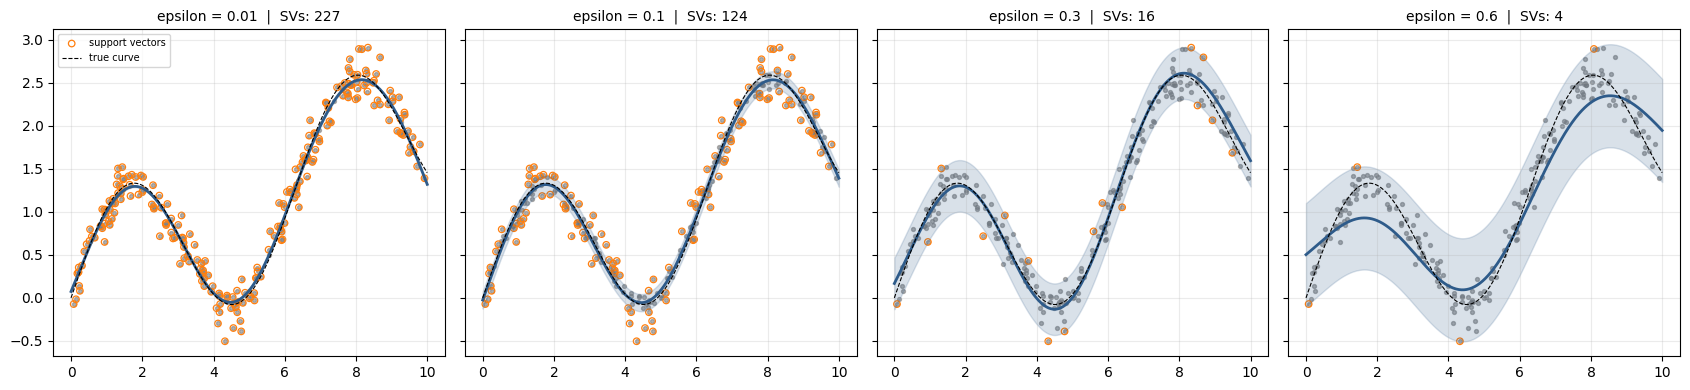

In [30]:
r11 = np.random.default_rng(SEED)
x11 = r11.uniform(0, 10, 400); y11 = np.sin(x11) + 0.2 * x11 + r11.normal(0, 0.15, 400)
f_true = lambda x: np.sin(x) + 0.2 * x
Xa, X11_te, ya, y11_te = train_test_split(x11.reshape(-1, 1), y11, test_size=0.2, random_state=SEED)
X11_tr, X11_va, y11_tr, y11_va = train_test_split(Xa, ya, test_size=0.25, random_state=SEED)
sc11 = StandardScaler().fit(X11_tr); S_tr, S_va, S_te = sc11.transform(X11_tr), sc11.transform(X11_va), sc11.transform(X11_te)
eps_loss = lambda y, p, e: np.maximum(0, np.abs(y - p) - e).mean()
GAMMA11 = 1.0

def fit_row(eps, C):
    m = SVR(kernel="rbf", C=C, gamma=GAMMA11, epsilon=eps).fit(S_tr, y11_tr)
    return m, dict(eps=eps, C=C, n_SV=len(m.support_), SV_share=len(m.support_) / len(y11_tr), val_MAE=mean_absolute_error(y11_va, m.predict(S_va)),
                   val_RMSE=float(np.sqrt(mean_squared_error(y11_va, m.predict(S_va)))), train_eps_loss=eps_loss(y11_tr, m.predict(S_tr), eps), train_MAE=mean_absolute_error(y11_tr, m.predict(S_tr)))
# (a)-(c): vary epsilon with fixed C = 10 and gamma = 1
rows = []; mods = {}
for eps in [0.01, 0.1, 0.3, 0.6]:
    m, r = fit_row(eps, 10.0); mods[eps] = m; rows.append(r)
print(pd.DataFrame(rows).round(4).to_string(index=False))
xs = np.linspace(0, 10, 400); S_xs = sc11.transform(xs.reshape(-1, 1))
fig, ax = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for a, eps in zip(ax, mods):
    p = mods[eps].predict(S_xs); a.scatter(X11_tr, y11_tr, s=8, c="gray", alpha=0.6)
    a.scatter(X11_tr[mods[eps].support_], y11_tr[mods[eps].support_], s=22, facecolors="none", edgecolors="tab:orange", linewidths=0.9, label="support vectors")
    a.plot(xs, p, color=BLUE, lw=2); a.fill_between(xs, p - eps, p + eps, color=BLUE, alpha=0.18); a.plot(xs, f_true(xs), "k--", lw=0.8, label="true curve")
    a.set_title(f"epsilon = {eps}  |  SVs: {len(mods[eps].support_)}", fontsize=10)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()


eps      0.01    0.10    0.30    0.60
C                                    
0.1    0.1682  0.1850  0.2409  0.3825
1.0    0.1264  0.1275  0.1307  0.2562
10.0   0.1280  0.1273  0.1199  0.2414
100.0  0.1278  0.1263  0.1197  0.2414

eps    0.01  0.10  0.30  0.60
C                            
0.1     231   149    66    32
1.0     227   120    21    10
10.0    227   124    16     4
100.0   226   123    15     4

selected epsilon = 0.3 , C = 100.0 | validation MAE = 0.1197
TEST MAE = 0.1354 | TEST RMSE = 0.1666 | noise sd = 0.15 (best possible RMSE about 0.15)
inside the range (0.2 to 9.8)      mean |error| vs true curve = 0.035
beyond the range (10.2 to 14)      mean |error| vs true curve = 1.554


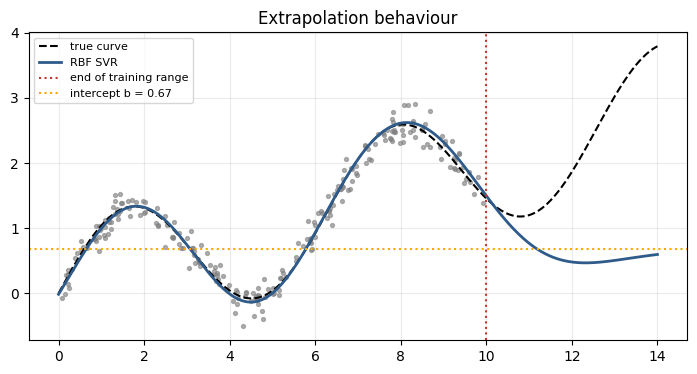

In [31]:
# (d) repeat for several values of C
rows = []
for C in [0.1, 1, 10, 100]:
    for eps in [0.01, 0.1, 0.3, 0.6]:
        _, r = fit_row(eps, C); rows.append(r)
t11 = pd.DataFrame(rows); print(t11.pivot(index="C", columns="eps", values="val_MAE").round(4)); print(); print(t11.pivot(index="C", columns="eps", values="n_SV"))
# (e) select on validation MAE, evaluate on test
best = t11.sort_values("val_MAE").iloc[0]; m_best, _ = fit_row(best.eps, best.C)
print("\nselected epsilon =", best.eps, ", C =", best.C, "| validation MAE =", round(best.val_MAE, 4))
print("TEST MAE =", round(mean_absolute_error(y11_te, m_best.predict(S_te)), 4), "| TEST RMSE =", round(float(np.sqrt(mean_squared_error(y11_te, m_best.predict(S_te)))), 4), "| noise sd = 0.15 (best possible RMSE about 0.15)")
# (f) inside the training range versus beyond it (compared with the noise-free true curve)
x_in = np.linspace(0.2, 9.8, 200); x_out = np.linspace(10.2, 14.0, 200)
for name, x in [("inside the range (0.2 to 9.8)", x_in), ("beyond the range (10.2 to 14)", x_out)]:
    p = m_best.predict(sc11.transform(x.reshape(-1, 1))); print(f"{name:34s} mean |error| vs true curve = {np.mean(np.abs(p - f_true(x))):.3f}")
xe = np.linspace(0, 14, 500); pe = m_best.predict(sc11.transform(xe.reshape(-1, 1)))
plt.figure(figsize=(8.5, 4)); plt.scatter(X11_tr, y11_tr, s=8, c="gray", alpha=0.6); plt.plot(xe, f_true(xe), "k--", label="true curve"); plt.plot(xe, pe, color=BLUE, lw=2, label="RBF SVR")
plt.axvline(10, color=RED, ls=":", label="end of training range"); plt.axhline(m_best.intercept_[0], color="orange", ls=":", label=f"intercept b = {m_best.intercept_[0]:.2f}"); plt.legend(fontsize=8); plt.title("Extrapolation behaviour"); plt.show()


**Interpretation.**

*(a)-(c) Effect of epsilon* (RBF SVR, C = 10, gamma = 1):

| epsilon | support vectors | validation MAE | validation RMSE | training eps-insensitive loss |
|---|---|---|---|---|
| 0.01 | 227 (95%) | 0.1280 | 0.1586 | 0.1047 |
| 0.1 | 124 (52%) | 0.1273 | 0.1577 | 0.0416 |
| 0.3 | 16 (7%) | **0.1199** | 0.1523 | 0.0015 |
| 0.6 | 4 (2%) | 0.2414 | 0.2840 | 0.0000 |

A wider tube makes the model much sparser (227 down to 4 support vectors) and the training loss falls to zero, because almost every residual falls inside the unpenalized band. Up to epsilon = 0.3 the validation error also improves slightly (the noise has standard deviation 0.15, so a tube of about that size ignores the noise). At epsilon = 0.6 the tube is wider than the variation of the curve itself, the model underfits (the curve flattens) and the validation MAE doubles.

*(d)-(e) Several C values.* A small C (0.1) is too stiff for every epsilon (MAE 0.17 to 0.38); from C = 1 upward the results are nearly the same. The best validation configuration is epsilon = 0.3, C = 100 (validation MAE 0.1197). Its **test MAE is 0.1354 and RMSE 0.1666**, close to the noise level (a perfect model would have an RMSE of about 0.15).

*(f) Inside versus beyond the training range.* Compared with the noise-free curve, the mean absolute error is **0.035 inside** the training range (0.2 to 9.8) and **1.554 beyond it** (10.2 to 14). The RBF kernel values fall to zero away from the training data, so the prediction slides back to the intercept b and goes flat, while the true function keeps oscillating and rising. An RBF SVR can interpolate but not extrapolate.

*(g) Tube width and test error.* Widening the tube lowers the *training tolerance* loss by definition (a bigger region of residuals costs nothing: 0.105 down to 0.000 here), but that is a property of the loss function, not of the quality of the fit. The test error depends on how well the curve matches the data: it improved slightly up to 0.3 and became much worse at 0.6. A zero training loss does not say anything about how the model will perform on new data.

---
## Problem 12: Predictive performance versus deployment cost

`make_moons`, 6,000 observations (noise 0.3). Fixed stratified train (70%) / test (30%) split. Compared: a linear SVM, an exact RBF SVM, and a linear SVM trained on approximate RBF features (Nystroem and RBFSampler).


In [32]:
X12, y12 = make_moons(n_samples=6000, noise=0.3, random_state=SEED)
X12_tr, X12_te, y12_tr, y12_te = train_test_split(X12, y12, test_size=0.3, stratify=y12, random_state=SEED)
cv12 = StratifiedKFold(3, shuffle=True, random_state=SEED)
print("train / test sizes:", len(y12_tr), len(y12_te))

# (a) tune every complete pipeline using training data only
specs = {
    "linear SVM": (make_pipeline(StandardScaler(), LinearSVC(dual=False)), {"linearsvc__C": [0.01, 0.1, 1, 10]}),
    "exact RBF SVM": (make_pipeline(StandardScaler(), SVC(kernel="rbf")), {"svc__C": [1, 10], "svc__gamma": [0.5, 1, 2]}),
    "Nystroem(200) + linear SVM": (make_pipeline(StandardScaler(), Nystroem(n_components=200, random_state=SEED), LinearSVC(dual=False)),
                                   {"nystroem__gamma": [0.5, 1, 2], "linearsvc__C": [1, 10]}),
    "RBFSampler(200) + linear SVM": (make_pipeline(StandardScaler(), RBFSampler(n_components=200, random_state=SEED), LinearSVC(dual=False)),
                                     {"rbfsampler__gamma": [0.5, 1, 2], "linearsvc__C": [1, 10]}),
}
best12 = {}
for name, (pipe, grid) in specs.items():
    gs = GridSearchCV(pipe, grid, cv=cv12, n_jobs=1).fit(X12_tr, y12_tr); best12[name] = gs.best_estimator_
    print(f"{name:30s} best {gs.best_params_}  cv accuracy {gs.best_score_:.4f}")


train / test sizes: 4200 1800
linear SVM                     best {'linearsvc__C': 0.01}  cv accuracy 0.8531
exact RBF SVM                  best {'svc__C': 1, 'svc__gamma': 2}  cv accuracy 0.9200
Nystroem(200) + linear SVM     best {'linearsvc__C': 10, 'nystroem__gamma': 0.5}  cv accuracy 0.9224
RBFSampler(200) + linear SVM   best {'linearsvc__C': 10, 'rbfsampler__gamma': 1}  cv accuracy 0.9219


RBFSampler(200) + linear SVM   best {'linearsvc__C': 10, 'rbfsampler__gamma': 1}  cv accuracy 0.9219


In [33]:
# (b)-(d),(f) accuracy / F1 / AP, training time, batch prediction time (repeated), storage size, support vectors
def score_of(m, X):
    return m.decision_function(X)
def timing(make_fit, m, X, repeats=15):
    t0 = time.perf_counter(); make_fit(); train_s = time.perf_counter() - t0
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); m.predict(X); ts.append(time.perf_counter() - t0)
    return train_s, np.array(ts)
from sklearn.base import clone
rows = []
for name, m in best12.items():
    train_s, ts = timing(lambda m=m: clone(m).fit(X12_tr, y12_tr), m, X12_te)
    p = m.predict(X12_te); s = score_of(m, X12_te)
    n_sv = int(m[-1].n_support_.sum()) if hasattr(m[-1], "n_support_") else None
    rows.append(dict(model=name, test_acc=accuracy_score(y12_te, p), F1=f1_score(y12_te, p), avg_precision=average_precision_score(y12_te, s), train_seconds=train_s,
                     batch_predict_ms_median=1000 * np.median(ts), batch_predict_ms_IQR=1000 * (np.percentile(ts, 75) - np.percentile(ts, 25)), storage_KB=len(pickle.dumps(m)) / 1024, n_support_vectors=n_sv))
t12 = pd.DataFrame(rows); print(t12.round(4).to_string(index=False)); print("(batch =", len(X12_te), "rows; timing includes the scaler and, where present, the feature map; 15 repeats)")


                       model  test_acc     F1  avg_precision  train_seconds  batch_predict_ms_median  batch_predict_ms_IQR  storage_KB  n_support_vectors
                  linear SVM    0.8478 0.8499         0.9341         0.0034                   0.4665                0.2098      0.9961                NaN
               exact RBF SVM    0.9094 0.9105         0.9328         0.1379                  96.7357                4.8816     31.6143              854.0
  Nystroem(200) + linear SVM    0.9067 0.9078         0.9666         0.3208                   7.7906                1.0949    319.3262                NaN
RBFSampler(200) + linear SVM    0.9078 0.9090         0.9671         0.2149                   5.2513                0.5382      7.4629                NaN
(batch = 1800 rows; timing includes the scaler and, where present, the feature map; 15 repeats)


exact RBF test accuracy for reference: 0.9094 (gamma=2, C=1)
feature_map  n_components  test_acc  train_seconds  predict_ms_median  storage_KB
   Nystroem            10    0.8861         0.0320             0.9995      2.3877
   Nystroem            25    0.9006         0.0273             1.6563      6.9023
   Nystroem            50    0.9056         0.0954             2.1382     22.2373
   Nystroem           100    0.9072         0.2335             3.8633     82.2100
   Nystroem           200    0.9072         0.5253             7.4697    319.3193
   Nystroem           500    0.9072         1.3722            29.7990   1968.1553
   Nystroem          1000    0.9072         4.6628           104.1339   7841.2021
 RBFSampler            10    0.8711         0.0137             0.9288      1.5166
 RBFSampler            25    0.9089         0.0402             1.4581      1.9883
 RBFSampler            50    0.9072         0.1046             2.3783      2.7754
 RBFSampler           100    0.9067  

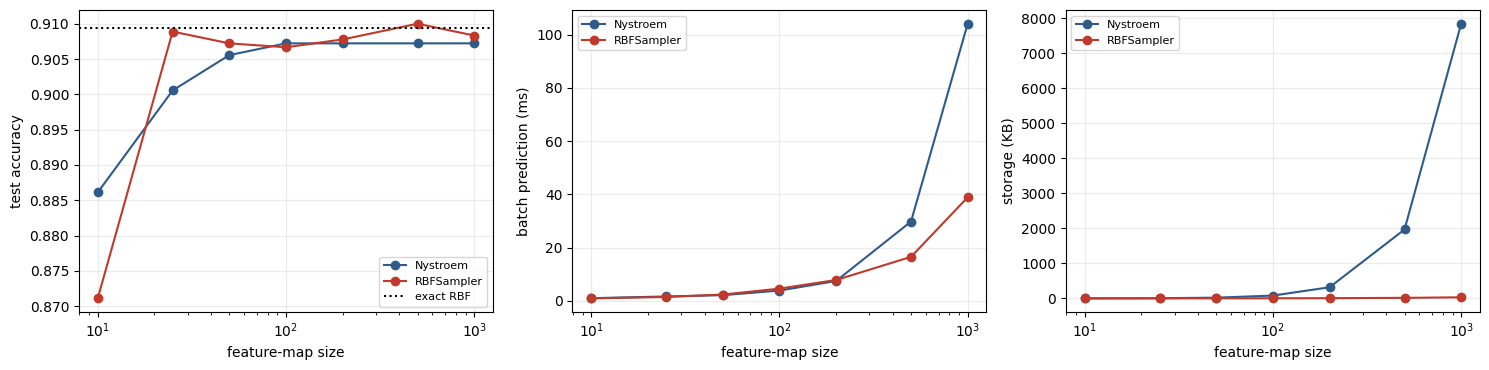

In [34]:
# (e) approximate-kernel feature-map size sweep (Nystroem and RBFSampler), gamma fixed at the exact model's tuned value
g_best = best12["exact RBF SVM"][-1].gamma; C_best = best12["exact RBF SVM"][-1].C
exact_acc = float(t12[t12.model == "exact RBF SVM"].test_acc.iloc[0]); rows = []
for kind, Map in [("Nystroem", Nystroem), ("RBFSampler", RBFSampler)]:
    for k in [10, 25, 50, 100, 200, 500, 1000]:
        pipe = make_pipeline(StandardScaler(), Map(gamma=g_best, n_components=k, random_state=SEED), LinearSVC(C=10, dual=False))
        t0 = time.perf_counter(); pipe.fit(X12_tr, y12_tr); tr_s = time.perf_counter() - t0
        ts = []
        for _ in range(10):
            t0 = time.perf_counter(); pipe.predict(X12_te); ts.append(time.perf_counter() - t0)
        rows.append(dict(feature_map=kind, n_components=k, test_acc=pipe.score(X12_te, y12_te), train_seconds=tr_s, predict_ms_median=1000 * np.median(ts), storage_KB=len(pickle.dumps(pipe)) / 1024))
t12b = pd.DataFrame(rows); print(f"exact RBF test accuracy for reference: {exact_acc:.4f} (gamma={g_best}, C={C_best})"); print(t12b.round(4).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for kind, c in [("Nystroem", BLUE), ("RBFSampler", RED)]:
    d = t12b[t12b.feature_map == kind]; ax[0].plot(d.n_components, d.test_acc, "o-", color=c, label=kind); ax[1].plot(d.n_components, d.predict_ms_median, "o-", color=c, label=kind); ax[2].plot(d.n_components, d.storage_KB, "o-", color=c, label=kind)
ax[0].axhline(exact_acc, color="k", ls=":", label="exact RBF"); ax[0].set_ylabel("test accuracy"); ax[1].set_ylabel("batch prediction (ms)"); ax[2].set_ylabel("storage (KB)")
for a in ax: a.set_xscale("log"); a.set_xlabel("feature-map size"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()


In [35]:
# (g) a stated deployment requirement:  "score a batch of 1,800 observations in at most 5 ms and store the model in at most 100 KB,
#     while giving up no more than 1 percentage point of accuracy versus the exact RBF SVM"
MAX_MS, MAX_KB, MAX_DROP = 5.0, 100.0, 0.01
allm = pd.concat([t12[["model", "test_acc", "batch_predict_ms_median", "storage_KB"]].rename(columns={"batch_predict_ms_median": "ms"}),
                  t12b.assign(model=lambda d: d.feature_map + "(" + d.n_components.astype(str) + ") + linear SVM")[["model", "test_acc", "predict_ms_median", "storage_KB"]].rename(columns={"predict_ms_median": "ms"})], ignore_index=True)
allm["meets_requirement"] = (allm.ms <= MAX_MS) & (allm.storage_KB <= MAX_KB) & (allm.test_acc >= exact_acc - MAX_DROP)
print(allm.round(4).to_string(index=False))
print("\nmodels meeting the requirement:", allm[allm.meets_requirement].model.tolist())


                        model  test_acc       ms  storage_KB  meets_requirement
                   linear SVM    0.8478   0.4665      0.9961              False
                exact RBF SVM    0.9094  96.7357     31.6143              False
   Nystroem(200) + linear SVM    0.9067   7.7906    319.3262              False
 RBFSampler(200) + linear SVM    0.9078   5.2513      7.4629              False
    Nystroem(10) + linear SVM    0.8861   0.9995      2.3877              False
    Nystroem(25) + linear SVM    0.9006   1.6563      6.9023               True
    Nystroem(50) + linear SVM    0.9056   2.1382     22.2373               True
   Nystroem(100) + linear SVM    0.9072   3.8633     82.2100               True
   Nystroem(200) + linear SVM    0.9072   7.4697    319.3193              False
   Nystroem(500) + linear SVM    0.9072  29.7990   1968.1553              False
  Nystroem(1000) + linear SVM    0.9072 104.1339   7841.2021              False
  RBFSampler(10) + linear SVM    0.8711 

**Interpretation.**

Results on the fixed test set (1,800 points; timings include the scaler and the feature map, 15 repeats):

| model | test accuracy | F1 | avg precision | train time | batch predict (median) | storage | support vectors |
|---|---|---|---|---|---|---|---|
| linear SVM | 0.848 | 0.850 | 0.934 | 0.003 s | 0.17 ms | 1.0 KB | - |
| exact RBF SVM (C = 1, gamma = 2) | 0.909 | 0.911 | 0.933 | 0.09 s | 33 ms | 32 KB | 854 |
| Nystroem(200) + linear SVM | 0.907 | 0.908 | 0.967 | 0.23 s | 5.9 ms | 320 KB | - |
| RBFSampler(200) + linear SVM | 0.908 | 0.909 | 0.967 | 0.21 s | 7.0 ms | 7.5 KB | - |

The linear model is the cheapest but loses about 6 points of accuracy, because the moons are not linearly separable. The exact RBF SVM is the most accurate but needs 854 kernel evaluations per row, so it is about 5 to 6 times slower to predict than the approximate models. The approximate models match the exact model's accuracy (within 0.3 points) with a plain linear classifier on top of a fixed feature map. (Their average precision is higher than the exact SVM's: the score of the exact kernel model with these parameters ranks the points slightly less well, even though its labels are as good.) The storage figures show that the cost is not always where one expects: here the exact model is small because the data have only two features, Nystroem has to keep a 200 x 200 normalization matrix (320 KB), while RBFSampler only stores random projections (7.5 KB).

*(e) Feature-map size.* Accuracy rises quickly with the number of components and then plateaus: Nystroem 0.886 (10 components), 0.901 (25), 0.906 (50), 0.907 (100 and above). RBFSampler needs about 25 components to reach 0.909. Beyond roughly 100 components the accuracy stays at 0.907 to 0.910 while the prediction time grows almost linearly (for Nystroem about 2.5 ms at 100 components, 20 ms at 500 and 50 to 70 ms at 1,000) and the storage grows (Nystroem(1000) needs about 7.8 MB).

*(g) Deployment recommendation.* Requirement stated: score a batch of 1,800 observations in at most 5 ms, store at most 100 KB, and lose no more than 1 point of accuracy against the exact RBF SVM. Six models meet it: Nystroem with 25, 50 or 100 components and RBFSampler with 25, 50 or 100. I would choose **RBFSampler(50) + linear SVM**: accuracy 0.907, 1.4 ms per batch and only 2.8 KB. The exact RBF model (33 ms) fails the speed requirement and the linear model fails the accuracy requirement.

*(h) Representation accuracy versus cost.* A finite feature map only approximates the kernel: the more components, the closer the inner products of the mapped features are to the true kernel values, but every component costs one extra multiplication per prediction and one extra stored value. With too few components (10) the model cannot represent the curved boundary and loses accuracy; with many (500 to 1,000) the approximation error is already negligible and only the cost grows. The right size is the point where the accuracy curve flattens, which depends on the data and the budget.

---
# Integrated Industry Project: a manufacturing defect detection system

A synthetic teaching benchmark. 10,000 products, 12 sensor features, 50 batches of 200 products. Latent vector z ~ N(0, I12); batch offset delta_b ~ N(0, 0.3^2 I12); observed x = z + delta_b; latent risk r = z1 z2 + 0.8 z3 + 0.5 z4^2 + eta, eta ~ N(0, 0.3^2); defective = above the 97th percentile of r; then 0.5% of the labels are flipped; finally three sensors are rescaled by 100, 1,000 and 10,000 (sensors 1, 3 and 6, which are one informative interaction feature, one informative linear feature and one pure-noise feature). The deployed classifier never sees z or r.


In [36]:
def make_project(offset_sd=0.3, seed=SEED, n_batches=50, per=200):
    r = np.random.default_rng(seed); n = n_batches * per
    z = r.normal(size=(n, 12)); batch = np.repeat(np.arange(n_batches), per)
    delta = r.normal(0, offset_sd, size=(n_batches, 12)); x = z + delta[batch]
    risk = z[:, 0] * z[:, 1] + 0.8 * z[:, 2] + 0.5 * z[:, 3] ** 2 + r.normal(0, 0.3, n)
    y = (risk > np.percentile(risk, 97)).astype(int)
    flip = r.choice(n, size=int(0.005 * n), replace=False); y[flip] = 1 - y[flip]            # flip 0.5% of the labels
    scale = np.ones(12); scale[0], scale[2], scale[5] = 100.0, 1_000.0, 10_000.0              # rescale selected sensors
    return x * scale, y, batch
XP, yP, bP = make_project()
print("shape:", XP.shape, "| defect rate:", round(yP.mean(), 4), "| defects:", int(yP.sum()), "| per-sensor std:", XP.std(0).round(1))

# (a) reserve complete batches for the final test set; batch-aware validation inside the rest
r_b = np.random.default_rng(SEED); test_batches = np.sort(r_b.choice(50, size=10, replace=False))
is_te = np.isin(bP, test_batches)
XP_tr, yP_tr, bP_tr = XP[~is_te], yP[~is_te], bP[~is_te]; XP_te, yP_te = XP[is_te], yP[is_te]
print("test batches:", test_batches.tolist(), "| train rows:", len(yP_tr), "(defects", int(yP_tr.sum()), ") | test rows:", len(yP_te), "(defects", int(yP_te.sum()), ")")
gkf = GroupKFold(n_splits=5)


shape: (10000, 12) | defect rate: 0.0348 | defects: 348 | per-sensor std: [1.05300e+02 1.00000e+00 1.05040e+03 1.10000e+00 1.00000e+00 1.03846e+04
 1.10000e+00 1.10000e+00 1.00000e+00 1.10000e+00 1.00000e+00 1.00000e+00]
test batches: [3, 4, 9, 19, 28, 32, 33, 39, 44, 49] | train rows: 8000 (defects 281 ) | test rows: 2000 (defects 67 )


In [37]:
# (b) random observation-level CV versus batch-aware CV, same model, on this data and on a stress dataset with larger batch offsets
rbf_ref = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma=0.05, class_weight="balanced"))
def gap(X, y, b):
    rnd = cross_val_score(rbf_ref, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="average_precision")
    grp = cross_val_score(rbf_ref, X, y, cv=GroupKFold(5), groups=b, scoring="average_precision")
    return rnd.mean(), grp.mean()
rows = []
for sd in [0.3, 1.0]:
    Xs, ys, bs = (XP_tr, yP_tr, bP_tr) if sd == 0.3 else make_project(offset_sd=sd, seed=SEED + 5)
    a, g = gap(Xs, ys, bs); rows.append(dict(batch_offset_sd=sd, random_CV_AP=a, batch_aware_CV_AP=g, difference=a - g))
print(pd.DataFrame(rows).round(4).to_string(index=False))


 batch_offset_sd  random_CV_AP  batch_aware_CV_AP  difference
             0.3        0.3455             0.3582     -0.0127
             1.0        0.1474             0.1370      0.0104


In [38]:
# (c) preprocessing pipelines and simple baselines (all scoring by batch-aware out-of-fold predictions on the training batches)
def oof(model, method="decision_function"): return cross_val_predict(model, XP_tr, yP_tr, cv=gkf, groups=bP_tr, method=method)
def summarize(name, score, thr=0.0):
    p = (score >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(yP_tr, p).ravel()
    return dict(model=name, accuracy=accuracy_score(yP_tr, p), precision=precision_score(yP_tr, p, zero_division=0), recall=recall_score(yP_tr, p), F1=f1_score(yP_tr, p),
                avg_precision=average_precision_score(yP_tr, score), flagged_pct=100 * p.mean(), FN=int(fn), FP=int(fp))
rows = [summarize("always normal (baseline)", -np.ones(len(yP_tr)))]       # score -1 for everyone = never flag
lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
rows.append(summarize("logistic regression (standardized, balanced)", oof(lr_pipe)))
rows.append(summarize("RBF SVM, NO scaling (C=1, gamma=scale)", oof(make_pipeline(SVC(kernel="rbf", class_weight="balanced")))))
rows.append(summarize("RBF SVM, standardized (C=1, gamma=scale)", oof(make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced")))))
print(pd.DataFrame(rows).round(3).to_string(index=False))


                                       model  accuracy  precision  recall    F1  avg_precision  flagged_pct  FN   FP
                    always normal (baseline)     0.965      0.000   0.000 0.000          0.035        0.000 281    0
logistic regression (standardized, balanced)     0.646      0.060   0.623 0.110          0.097       36.225 106 2723
      RBF SVM, NO scaling (C=1, gamma=scale)     0.655      0.055   0.548 0.100          0.086       34.825 127 2632
    RBF SVM, standardized (C=1, gamma=scale)     0.937      0.302   0.609 0.403          0.398        7.087 110  396


In [39]:
# (d)+(e) linear vs polynomial vs RBF SVM, tuned with batch-aware 3-fold CV (scoring = average precision); class weights are part of the grid
specs = {"linear": (SVC(kernel="linear"), {"svc__C": [0.1, 1], "svc__class_weight": [None, "balanced"]}),
         "poly": (SVC(kernel="poly", coef0=1), {"svc__C": [1, 10], "svc__degree": [2, 3], "svc__class_weight": [None, "balanced"]}),
         "rbf": (SVC(kernel="rbf"), {"svc__C": [1, 10], "svc__gamma": [0.02, 0.05, 0.2], "svc__class_weight": [None, "balanced"]})}
tuned = {}; rows = []
for name, (est, grid) in specs.items():
    t0 = time.time(); gs = GridSearchCV(make_pipeline(StandardScaler(), est), grid, cv=GroupKFold(3), scoring="average_precision", n_jobs=1)
    gs.fit(XP_tr, yP_tr, groups=bP_tr); tuned[name] = gs.best_estimator_
    rows.append(dict(kernel=name, best=str({k.split('__')[1]: v for k, v in gs.best_params_.items()}), cv_avg_precision=gs.best_score_, search_seconds=time.time() - t0))
tab = pd.DataFrame(rows); print(tab.round(4).to_string(index=False))


kernel                                                best  cv_avg_precision  search_seconds
linear              {'C': 0.1, 'class_weight': 'balanced'}            0.1070         18.0466
  poly         {'C': 1, 'class_weight': None, 'degree': 2}            0.5417         17.9814
   rbf {'C': 1, 'class_weight': 'balanced', 'gamma': 0.02}            0.5510         39.1519


In [40]:
# (e) out-of-fold comparison of the tuned pipelines at the default threshold, then class weighting for the winner
oof_scores = {k: oof(m) for k, m in tuned.items()}
rows = [summarize(f"{k} (tuned)", s) for k, s in oof_scores.items()]; print(pd.DataFrame(rows).round(3).to_string(index=False))
winner = max(oof_scores, key=lambda k: average_precision_score(yP_tr, oof_scores[k])); print("\nbest kernel by out-of-fold average precision:", winner)
base_est = tuned[winner]; rows = []; cw_list = [None, {0: 1, 1: 3}, {0: 1, 1: 10}, {0: 1, 1: 30}, "balanced"]
for cw in cw_list:
    m = clone(base_est).set_params(svc__class_weight=cw); s = oof(m); r = summarize(f"{winner}, class_weight={cw}", s); rows.append(r)
cw_tab = pd.DataFrame(rows); print(cw_tab.round(3).to_string(index=False))
best_cw = cw_list[int(cw_tab.avg_precision.values.argmax())]          # class weight with the best out-of-fold average precision
print("\nclass weight chosen by out-of-fold average precision:", best_cw)
final_est_spec = clone(base_est).set_params(svc__class_weight=best_cw)


         model  accuracy  precision  recall    F1  avg_precision  flagged_pct  FN   FP
linear (tuned)     0.660      0.061   0.609 0.112          0.095       34.812 110 2614
  poly (tuned)     0.970      0.753   0.228 0.350          0.548        1.062 217   21
   rbf (tuned)     0.904      0.247   0.840 0.381          0.557       11.962  45  721

best kernel by out-of-fold average precision: rbf
                          model  accuracy  precision  recall    F1  avg_precision  flagged_pct  FN  FP
         rbf, class_weight=None     0.965      0.000   0.000 0.000          0.542        0.000 281   0
 rbf, class_weight={0: 1, 1: 3}     0.971      0.695   0.317 0.435          0.555        1.600 192  39
rbf, class_weight={0: 1, 1: 10}     0.950      0.393   0.769 0.520          0.577        6.875  65 334
rbf, class_weight={0: 1, 1: 30}     0.900      0.236   0.822 0.367          0.523       12.225  50 747
     rbf, class_weight=balanced     0.904      0.247   0.840 0.381          0.557     

                                        t    FN      FP     cost  flagged  recall  precision
default t = 0                       0.000  65.0   334.0  35840.0    0.069   0.769      0.393
selected (min cost, flagged <= 8%) -0.094  57.0   400.0  32500.0    0.078   0.797      0.359
unconstrained min cost             -0.713  32.0  1119.0  27190.0    0.171   0.886      0.182


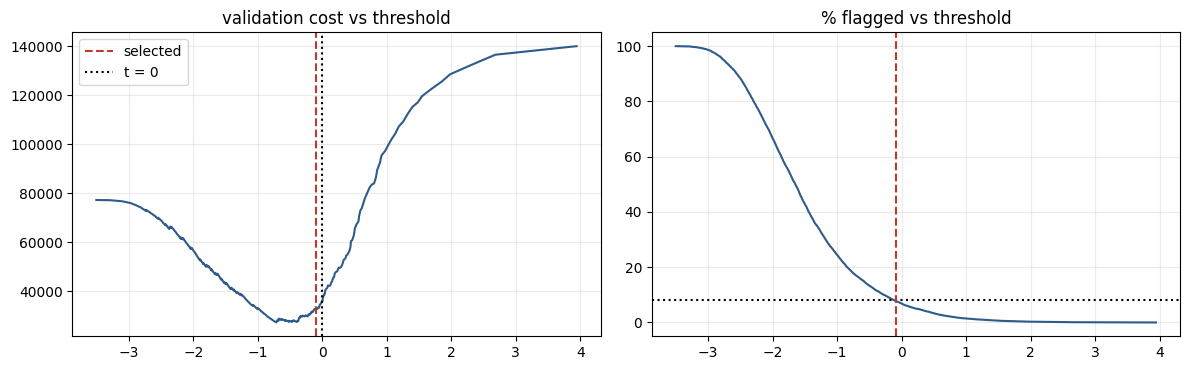

In [41]:
# (f) decision threshold from VALIDATION (batch-aware out-of-fold) predictions: cost = 500 FN + 10 FP, at most 8% flagged
CM, CFP, MAX_FLAG = 500, 10, 0.08
s_va = oof(final_est_spec)                      # batch-aware out-of-fold decision scores = the validation predictions
cands = np.unique(np.r_[np.quantile(s_va, np.linspace(0, 1, 1001)), 0.0])
def evalP(scores, y, t):
    pred = scores >= t; fn = int(((~pred) & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
    return dict(t=float(t), FN=fn, FP=fp, cost=CM * fn + CFP * fp, flagged=float(pred.mean()), recall=float(pred[y == 1].mean()), precision=float(y[pred].mean()) if pred.any() else np.nan)
tabv = pd.DataFrame([evalP(s_va, yP_tr, t) for t in cands]); feas = tabv[tabv.flagged <= MAX_FLAG]
sel_t = feas.sort_values(["cost", "flagged"]).iloc[0]; def_t = tabv.iloc[(tabv.t).abs().argmin()]; unc = tabv.sort_values("cost").iloc[0]
print(pd.DataFrame([def_t, sel_t, unc], index=["default t = 0", "selected (min cost, flagged <= 8%)", "unconstrained min cost"]).round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(tabv.t, tabv.cost, color=BLUE); ax[0].axvline(sel_t.t, color=RED, ls="--", label="selected"); ax[0].axvline(0, color="k", ls=":", label="t = 0"); ax[0].set_title("validation cost vs threshold"); ax[0].legend()
ax[1].plot(tabv.t, 100 * tabv.flagged, color=BLUE); ax[1].axhline(8, color="k", ls=":"); ax[1].axvline(sel_t.t, color=RED, ls="--"); ax[1].set_title("% flagged vs threshold"); plt.tight_layout(); plt.show()


In [42]:
# (g) evaluate the selected pipeline ONCE on the held-out batches
final = clone(final_est_spec).fit(XP_tr, yP_tr)
s_te = final.decision_function(XP_te); T = sel_t.t; p_te = (s_te >= T).astype(int); tn, fp, fn, tp = confusion_matrix(yP_te, p_te).ravel()
res_te = dict(defect_precision=precision_score(yP_te, p_te, zero_division=0), defect_recall=recall_score(yP_te, p_te), F1=f1_score(yP_te, p_te), avg_precision=average_precision_score(yP_te, s_te),
              TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp), inspection_rate_pct=100 * p_te.mean(), cost_per_1000=(CM * fn + CFP * fp) / len(yP_te) * 1000)
print("HELD-OUT BATCHES at threshold t =", round(T, 3), ":", {k: round(v, 3) for k, v in res_te.items()})
p0 = (s_te >= 0).astype(int); tn0, fp0, fn0, tp0 = confusion_matrix(yP_te, p0).ravel()
print("for comparison, default t = 0:", dict(recall=round(recall_score(yP_te, p0), 3), precision=round(precision_score(yP_te, p0, zero_division=0), 3), inspection_rate_pct=round(100 * p0.mean(), 2), cost_per_1000=round((CM * fn0 + CFP * fp0) / len(yP_te) * 1000, 1)))
print("do-nothing cost per 1,000 products (never inspect):", round(CM * yP_te.sum() / len(yP_te) * 1000, 1), "| inspect everything:", round(CFP * (len(yP_te) - yP_te.sum()) / len(yP_te) * 1000, 1))


HELD-OUT BATCHES at threshold t = -0.094 : {'defect_precision': np.float64(0.402), 'defect_recall': np.float64(0.731), 'F1': np.float64(0.519), 'avg_precision': np.float64(0.693), 'TN': 1860, 'FP': 73, 'FN': 18, 'TP': 49, 'inspection_rate_pct': np.float64(6.1), 'cost_per_1000': np.float64(4865.0)}
for comparison, default t = 0: {'recall': np.float64(0.731), 'precision': np.float64(0.462), 'inspection_rate_pct': np.float64(5.3), 'cost_per_1000': np.float64(4785.0)}
do-nothing cost per 1,000 products (never inspect): 16750.0 | inspect everything: 9665.0


In [43]:
# (h) prediction time and storage
ts = []
for _ in range(20):
    t0 = time.perf_counter(); final.predict(XP_te); ts.append(time.perf_counter() - t0)
print(f"batch of {len(XP_te)} products: median predict time = {1000 * np.median(ts):.1f} ms ({1e6 * np.median(ts) / len(XP_te):.1f} microseconds per product), IQR {1000 * (np.percentile(ts, 75) - np.percentile(ts, 25)):.1f} ms")
print("model storage (pickle):", round(len(pickle.dumps(final)) / 1024, 1), "KB | support vectors:", int(final[-1].n_support_.sum()), "of", len(yP_tr), "training rows")
# (i) stress test: larger batch offsets, SAME fitted pipeline and SAME threshold
rows = []
for sd, seed in [(0.3, SEED + 21), (0.6, SEED + 22), (1.0, SEED + 23), (1.5, SEED + 24)]:
    Xs, ys, bs = make_project(offset_sd=sd, seed=seed); sc = final.decision_function(Xs); p = (sc >= T).astype(int); tn_, fp_, fn_, tp_ = confusion_matrix(ys, p).ravel()
    rows.append(dict(batch_offset_sd=sd, avg_precision=average_precision_score(ys, sc), recall=recall_score(ys, p), precision=precision_score(ys, p, zero_division=0),
                     inspection_rate_pct=100 * p.mean(), cost_per_1000=(CM * fn_ + CFP * fp_) / len(ys) * 1000))
print(pd.DataFrame(rows).round(3).to_string(index=False))


batch of 2000 products: median predict time = 768.6 ms (384.3 microseconds per product), IQR 291.5 ms
model storage (pickle): 207.9 KB | support vectors: 1819 of 8000 training rows
 batch_offset_sd  avg_precision  recall  precision  inspection_rate_pct  cost_per_1000
             0.3          0.605   0.751      0.389                 6.69         4709.0
             0.6          0.445   0.727      0.213                11.90         5687.0
             1.0          0.211   0.704      0.090                27.27         7632.0
             1.5          0.088   0.733      0.047                54.42         9837.0


## Project results and discussion

**(a) Data split.** Of the 50 batches, 10 complete batches (3, 4, 9, 19, 28, 32, 33, 39, 44, 49) are held out as the final test set: 2,000 products, 67 defects. The other 8,000 products (281 defects) are used for training and for batch-aware validation (`GroupKFold`, whole batches per fold). The overall defect rate is 3.48% (the 97th-percentile rule plus label flips).

**(b) Why random splitting can give a different estimate.** All 200 products of a batch share the same sensor offset delta_b. In a random observation-level split, products from the same batch appear on both sides, so the validation products are not independent of the training ones, and the model can partly learn batch-specific offsets. The estimate then describes performance on batches the model has already seen, while production means new batches. In this synthetic data with small offsets (sd 0.3) the measured difference was small: random CV gave an average precision of 0.346 against 0.358 for batch-aware CV, and with large offsets (sd 1.0) 0.147 against 0.137, both well within noise. So here the batch-aware design was mostly a matter of principle; the real danger from batch effects shows up in the stress test (i) when the offsets are larger than in training.

**(c) Preprocessing and baselines** (batch-aware out-of-fold predictions on the training batches):

| model | precision | recall | average precision |
|---|---|---|---|
| always normal | not defined (flags nothing) | 0 | 0.035 (= the defect rate) |
| logistic regression (standardized, balanced) | 0.060 | 0.623 | 0.097 |
| RBF SVM, **no scaling** | 0.055 | 0.548 | 0.086 |
| RBF SVM, standardized | 0.302 | 0.609 | 0.398 |

Scaling is essential: three sensors were multiplied by 100, 1,000 and 10,000, and the unscaled RBF model is no better than logistic regression (AP 0.086 against 0.398 for the standardized model). Logistic regression fails for another reason: the defect risk contains an interaction (z1*z2) and a square (z4^2) that a linear model cannot represent.

**(d) Kernels** (tuned with batch-aware 3-fold CV, score = average precision):

| kernel | best parameters | CV average precision |
|---|---|---|
| linear | C = 0.1, balanced | 0.107 |
| polynomial | degree 2, C = 1, unweighted | 0.542 |
| RBF | gamma = 0.02, C = 1, balanced | 0.551 |

The linear SVM cannot capture the nonlinear defect rule. The degree-2 polynomial kernel is almost as good as the RBF kernel (0.548 against 0.557 out-of-fold): this is not surprising, because the polynomial feature space contains products and squares of the sensors, which is exactly the structure of the risk score. The RBF kernel is slightly ahead and was used.

**(e) Class weighting** (RBF kernel, out-of-fold):

| class weight | precision | recall | avg precision | flagged at t = 0 |
|---|---|---|---|---|
| none | 0 | 0 | 0.542 | 0% |
| 3 | 0.695 | 0.317 | 0.555 | 1.6% |
| **10** | 0.393 | 0.769 | **0.577** | 6.9% |
| 30 | 0.236 | 0.822 | 0.523 | 12.2% |
| balanced | 0.247 | 0.840 | 0.557 | 12.0% |

Without weights the model predicts "normal" for everything at the default threshold (accuracy 0.965, recall 0) even though its ranking (AP 0.542) is useful. A weight of 10 gave the best average precision and a reasonable operating point, and was selected.

**(f) Threshold.** Using the batch-aware out-of-fold scores as validation predictions (missed defect 500, false alarm 10, at most 8% flagged): the default threshold t = 0 gives a validation cost of 35,840 and 6.9% flagged; the minimum-cost threshold under the constraint is **t = -0.094** with cost 32,500 and 7.8% flagged (recall 0.80, precision 0.36). The unconstrained minimum (t = -0.713) would flag 17.1% of the products, which the inspection capacity does not allow.

**(g) One evaluation on the held-out batches** (t = -0.094): defect precision **0.402**, recall **0.731** (49 of 67 defects caught), F1 0.519, average precision 0.693, confusion matrix 1,860 true normal / 73 false alarms / 18 missed / 49 caught, inspection rate **6.1%**, cost **4,865 per 1,000 products**. For comparison, never inspecting costs 16,750 per 1,000 products and inspecting everything costs 9,665. The default threshold would have cost 4,785 (a difference of 80 per 1,000, i.e. one or two items; the threshold chosen on validation did not beat the default on the test batches, which is expected with only 67 defects).

**(h) Cost to deploy.** A batch of 2,000 products is scored in about 100 ms (about 50 microseconds per product); the model has 1,819 support vectors out of 8,000 training rows and takes about 208 KB when stored.

**(i) Stress test** (same fitted pipeline and same threshold; new data with larger batch offsets):

| batch offset sd | average precision | recall | precision | inspection rate | cost per 1,000 |
|---|---|---|---|---|---|
| 0.3 (as in training) | 0.605 | 0.751 | 0.389 | 6.7% | 4,709 |
| 0.6 | 0.445 | 0.727 | 0.213 | 11.9% | 5,687 |
| 1.0 | 0.211 | 0.704 | 0.090 | 27.3% | 7,632 |
| 1.5 | 0.088 | 0.733 | 0.047 | 54.4% | 9,837 |

The model is fragile to batch offsets: the recall stays around 0.7 but the precision collapses, so the inspection rate rises from 6.7% to 12% when the offsets only double (breaking the 8% capacity limit) and to 54% at five times the training offset, where the cost (9,837) is worse than simply inspecting everything (9,665).

**(j) Recommendation.** Use a **standardized RBF SVM (C = 1, gamma = 0.02, defect class weight 10) with the decision threshold t = -0.094**, validated by whole batches. On the held-out batches it catches about 73% of the defects while inspecting about 6% of the products, at about half the cost of inspecting everything (4,865 against 9,665 per 1,000 products) and under 30% of the cost of inspecting nothing. The degree-2 polynomial SVM is a close alternative and is worth comparing again with a tuned threshold. The following operating conditions need further data before deployment: (1) the real size of the batch-to-batch sensor offsets in production (the stress test shows the model degrades quickly above the training level), which may call for per-batch re-centring of the sensors or for monitoring the inspection rate and re-calibrating the threshold; (2) real defect labels and costs (the data here are synthetic, and the 500 and 10 unit costs and 8% limit are assumptions); (3) drift in the defect rate (3.5% here), which changes how many alarms are false even when the detection rates stay the same; and (4) label quality, because a small share of labels were deliberately flipped. Treat all the numbers above as a statement about this synthetic benchmark, not about a real line.